# Modul 6 — Təbii dilin emalı (Natural Language Processing, NLP)
### Mətndən rəqəmlərə, rəqəmlərdən dil modellərinə

Kompüter mətni "oxuya" bilmir — o yalnız rəqəmlərlə işləyir. **NLP**-nin bütün işi bir sualın ətrafında fırlanır:
**mətni rəqəmlərə necə çevirək ki, mənası itməsin?**

Bu notebook-da bu yolu addım-addım keçirik:

| № | Mövzu | Bölmə |
|---|-------|-------|
| 1 | NLTK ilə əsas tapşırıqlar: tokenləşdirmə, stemminq, lemmatizasiya, stop sözlər | 1 |
| 2 | NLP-də tipik tapşırıqlar (case-lər) | 2 |
| 3 | Aralıq təsvirlərin seçilməsi: one-hot, Bag-of-Words, TF-IDF, embedding | 3 |
| 4 | Aralıq təsvirlərin yaradılması: Word2Vec və GloVe | 4 |
| 5 | Praktiki nümunə: Word2Vec ilə rəylərin təsnifatı | 5 |
| 6 | Dil modelləri | 6 |
| 7 | Seq-to-seq: RNN, LSTM, Transformer | 7 |
| 8 | Praktiki nümunə: simvol səviyyəli RNN ilə ad generasiyası | 8 |
| 9 | Transfer learning | 9 |

> 💡 Notebook Google Colab-da işləmək üçün hazırlanıb. Bölmə 8 və 9 üçün GPU arzuolunandır
> (*Runtime → Change runtime type → T4 GPU*), amma CPU-da da işləyir, sadəcə bir az yavaş.

## 0. Hazırlıq

In [ ]:
# Colab-da torch, sklearn, pandas artıq var. Çatışmayanları quraşdırırıq:
%pip install -q nltk gensim transformers

In [2]:
import re
import math
import random
import string
import time
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.15.0 | device: cpu


In [4]:
import nltk

# NLTK-nın lüğətləri və modelləri ayrıca yüklənir (bir dəfə).
# Bəzi resursların adları NLTK-nın yeni versiyalarında dəyişib, ona görə hər iki adı yükləyirik.
for res in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng",
            "maxent_ne_chunker", "maxent_ne_chunker_tab", "words",
            "vader_lexicon", "movie_reviews"]:
    nltk.download(res, quiet=True)
print("NLTK:", nltk.__version__)

NLTK: 3.10.4


## 1. NLTK ilə mətnin ilkin emalı

**NLTK (Natural Language Toolkit)** — Python-da NLP üçün ən köhnə və ən "tədrisə uyğun" kitabxanadır.
Mətnlə hər hansı işə başlamazdan əvvəl onu təmizləyib hissələrə bölürük. Buna **ilkin emal (preprocessing)** deyilir.

Tipik ardıcıllıq:

```
Xam mətn → Tokenləşdirmə → Kiçik hərflər → Stop sözlərin silinməsi → Stemminq / Lemmatizasiya → Təmiz tokenlər
```

### 1.1. Tokenləşdirmə (Tokenization)

**Token** — mətnin ən kiçik "vahidi": söz, rəqəm, durğu işarəsi. **Tokenləşdirmə** mətni bu vahidlərə bölməkdir.

Niyə sadəcə `text.split()` kifayət deyil? Çünki:
- `"today."` — nöqtə sözə yapışıb qalır;
- `"didn't"` → əslində iki hissədir: `did` + `n't`;
- `"Dr."` — burada nöqtə cümlənin sonu deyil!

In [5]:
from nltk.tokenize import sent_tokenize, word_tokenize, wordpunct_tokenize, RegexpTokenizer

text = ("Dr. Smith didn't come to the office today. He's working from home! "
        "The new laptop costs $1,299.99 — isn't it expensive?")

print("split()          :", text.split())
print()
print("sent_tokenize    :", sent_tokenize(text))     # cümlələrə bölmə
print()
print("word_tokenize    :", word_tokenize(text))     # sözlərə bölmə (ağıllı)
print()
print("wordpunct_tokenize:", wordpunct_tokenize(text))  # hər durğu işarəsi ayrı token

split()          : ['Dr.', 'Smith', "didn't", 'come', 'to', 'the', 'office', 'today.', "He's", 'working', 'from', 'home!', 'The', 'new', 'laptop', 'costs', '$1,299.99', '—', "isn't", 'it', 'expensive?']

sent_tokenize    : ["Dr. Smith didn't come to the office today.", "He's working from home!", "The new laptop costs $1,299.99 — isn't it expensive?"]

word_tokenize    : ['Dr.', 'Smith', 'did', "n't", 'come', 'to', 'the', 'office', 'today', '.', 'He', "'s", 'working', 'from', 'home', '!', 'The', 'new', 'laptop', 'costs', '$', '1,299.99', '—', 'is', "n't", 'it', 'expensive', '?']

wordpunct_tokenize: ['Dr', '.', 'Smith', 'didn', "'", 't', 'come', 'to', 'the', 'office', 'today', '.', 'He', "'", 's', 'working', 'from', 'home', '!', 'The', 'new', 'laptop', 'costs', '$', '1', ',', '299', '.', '99', '—', 'isn', "'", 't', 'it', 'expensive', '?']


Diqqət edin:
- `sent_tokenize` `"Dr."`-dən sonra cümləni bölmədi — o, abreviaturaları tanıyır;
- `word_tokenize` `"didn't"`-i `did` + `n't`-ə böldü, `$1,299.99`-u isə bir ədəd kimi saxladı;
- `wordpunct_tokenize` daha "kobud"dur — hər durğu işarəsində bölür.

**Azərbaycan dili** üçün NLTK-da xüsusi tokenizator yoxdur, amma sadə hallarda requlyar ifadə (regex) kifayət edir:

In [6]:
az_text = "Bakı Azərbaycanın paytaxtıdır. Şəhərdə 2 milyondan çox insan yaşayır! Sən də Bakıya gəlmisən?"

print(word_tokenize(az_text))

# \w+ — hərf/rəqəmlərdən ibarət ardıcıllıq (ə, ş, ğ, ı, ö, ü, ç da daxil)
tokenizer = RegexpTokenizer(r"\w+")
print(tokenizer.tokenize(az_text.lower()))

['Bakı', 'Azərbaycanın', 'paytaxtıdır', '.', 'Şəhərdə', '2', 'milyondan', 'çox', 'insan', 'yaşayır', '!', 'Sən', 'də', 'Bakıya', 'gəlmisən', '?']
['bakı', 'azərbaycanın', 'paytaxtıdır', 'şəhərdə', '2', 'milyondan', 'çox', 'insan', 'yaşayır', 'sən', 'də', 'bakıya', 'gəlmisən']


### 1.2. Stemminq (Stemming) — sözün "kökünü kəsmək"

**Stemminq** — sözün sonundakı şəkilçiləri **sadə qaydalarla** kəsib atmaqdır. Məqsəd: `running`, `runs`, `runner` kimi formaları bir tokenə gətirmək.

Stemmer lüğətdən istifadə etmir — sadəcə qaydalar: "*sonu `-ing`-dirsə, kəs*", "*sonu `-ies`-dirsə, `-i` ilə əvəz et*" və s.
Ona görə də nəticə həmişə real söz olmur (`studies` → `studi`).

NLTK-da 3 məşhur stemmer var:
- **Porter** — klassik, mülayim;
- **Snowball (Porter2)** — Porter-in təkmilləşdirilmiş versiyası, bir neçə dili dəstəkləyir;
- **Lancaster** — ən "aqressiv", çox qısaldır.

In [7]:
from nltk.stem import PorterStemmer, SnowballStemmer, LancasterStemmer

porter = PorterStemmer()
snowball = SnowballStemmer("english")
lancaster = LancasterStemmer()

words = ["running", "runs", "ran", "runner", "easily", "fairly", "studies", "studying",
         "better", "generous", "generation", "university", "universe", "organization", "organ"]

pd.DataFrame({
    "söz": words,
    "Porter": [porter.stem(w) for w in words],
    "Snowball": [snowball.stem(w) for w in words],
    "Lancaster": [lancaster.stem(w) for w in words],
})

,söz,Porter,Snowball,Lancaster
0,running,run,run,run
1,runs,run,run,run
2,ran,ran,ran,ran
3,runner,runner,runner,run
4,easily,easili,easili,easy
5,fairly,fairli,fair,fair
6,studies,studi,studi,study
7,studying,studi,studi,study
8,better,better,better,bet
9,generous,gener,generous,gen


Stemminqin problemləri cədvəldə yaxşı görünür:
- **Həddən artıq kəsmə (over-stemming):** `university` və `universe` → `univers` — mənaları tam fərqli sözlər birləşdi; `organization` və `organ` (Lancaster) — eyni.
- **Az kəsmə (under-stemming):** `ran` və `run` birləşmədi — stemmer bilmir ki, `ran` — `run`-ın keçmiş zamanıdır.

👉 Stemminq **sürətlidir**, axtarış sistemlərində və sadə təsnifatda yaxşı işləyir, amma "dəqiq" deyil.

### 1.3. Lemmatizasiya (Lemmatization) — sözün lüğət formasını tapmaq

**Lemma** — sözün lüğətdə yazılan forması: `ran` → `run`, `better` → `good`, `mice` → `mouse`.
**Lemmatizator** qaydalarla yox, **lüğətlə** (NLTK-da — WordNet) işləyir, ona görə nəticə həmişə real sözdür.

Amma bir şərt var: lemmatizator sözün **nitq hissəsini (POS)** bilməlidir. `"meeting"` isimdirsə (*görüş*) — `meeting` qalır, feildirsə (*görüşmək*) — `meet` olur.

In [8]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

# pos: n — isim (noun), v — feil (verb), a — sifət (adjective), r — zərf (adverb)
examples = [("running", "n"), ("running", "v"), ("ran", "v"), ("better", "a"),
            ("studies", "n"), ("studies", "v"), ("mice", "n"), ("geese", "n"),
            ("was", "v"), ("meeting", "n"), ("meeting", "v")]

pd.DataFrame({
    "söz": [w for w, _ in examples],
    "POS": [p for _, p in examples],
    "lemma": [lemmatizer.lemmatize(w, pos=p) for w, p in examples],
    "Porter stem": [porter.stem(w) for w, _ in examples],
})

,söz,POS,lemma,Porter stem
0,running,n,running,run
1,running,v,run,run
2,ran,v,run,ran
3,better,a,good,better
4,studies,n,study,studi
5,studies,v,study,studi
6,mice,n,mouse,mice
7,geese,n,goose,gees
8,was,v,be,wa
9,meeting,n,meeting,meet


POS-u əl ilə yazmaq əlverişsizdir. NLTK-nın `pos_tag` funksiyası sözlərin nitq hissəsini avtomatik təyin edir.
Onun teqlərini (`NN`, `VBD`, `JJ`...) WordNet-in formatına (`n`, `v`, `a`, `r`) çevirib lemmatizatora veririk:

In [9]:
from nltk import pos_tag
from nltk.corpus import wordnet


def to_wordnet_pos(treebank_tag):
    # Penn Treebank teqini (NN, VBD, JJ, RB...) WordNet formatına çeviririk
    if treebank_tag.startswith("J"):
        return wordnet.ADJ
    if treebank_tag.startswith("V"):
        return wordnet.VERB
    if treebank_tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN


def lemmatize_sentence(sentence):
    tokens = word_tokenize(sentence)
    tagged = pos_tag(tokens)
    return [lemmatizer.lemmatize(w.lower(), to_wordnet_pos(t)) for w, t in tagged]


s = "The children were playing in the gardens and the mice ran away from the better cats"
print("POS teqləri:", pos_tag(word_tokenize(s)))
print()
print("Lemmalar   :", lemmatize_sentence(s))
print("Stemlər    :", [porter.stem(w) for w in word_tokenize(s)])

POS teqləri: [('The', 'DT'), ('children', 'NNS'), ('were', 'VBD'), ('playing', 'VBG'), ('in', 'IN'), ('the', 'DT'), ('gardens', 'NNS'), ('and', 'CC'), ('the', 'DT'), ('mice', 'NN'), ('ran', 'VBD'), ('away', 'RB'), ('from', 'IN'), ('the', 'DT'), ('better', 'JJR'), ('cats', 'NNS')]

Lemmalar   : ['the', 'child', 'be', 'play', 'in', 'the', 'garden', 'and', 'the', 'mouse', 'run', 'away', 'from', 'the', 'good', 'cat']
Stemlər    : ['the', 'children', 'were', 'play', 'in', 'the', 'garden', 'and', 'the', 'mice', 'ran', 'away', 'from', 'the', 'better', 'cat']


| | Stemminq | Lemmatizasiya |
|---|---|---|
| Necə işləyir | Qaydalarla şəkilçini kəsir | Lüğətdə lemmanı axtarır |
| Nəticə | Həmişə real söz deyil (`studi`) | Həmişə real söz (`study`) |
| Sürət | Çox sürətli | Daha yavaş (POS lazımdır) |
| Nə vaxt | Axtarış, böyük həcmli mətn, sadə modellər | Mənanın vacib olduğu yerlər, chatbot-lar, analiz |

> 🇦🇿 **Azərbaycan dili haqqında:** bizim dil **aqlütinativdir** — şəkilçilər bir-birinin ardınca "yapışır":
> *ev → evlər → evlərimiz → evlərimizdən*. Bir kökdən yüzlərlə forma yaranır, ona görə stemminq/lemmatizasiya bizim dil üçün
> ingilis dilindən də vacibdir. NLTK-da Azərbaycan dili üçün hazır stemmer yoxdur, amma sadə bir versiyanı özümüz yaza bilərik:

In [10]:
# Çox sadə Azərbaycan dili stemmeri: sözün sonundan tanınmış şəkilçiləri təkrar-təkrar kəsir.
# (Real layihələrdə daha mürəkkəb morfoloji analizatorlar istifadə olunur.)
AZ_SUFFIXES = sorted([
    "lar", "lər",                                   # cəm
    "ın", "in", "un", "ün", "nın", "nin", "nun", "nün",  # yiyəlik hal
    "da", "də", "dan", "dən", "ta", "tə", "tan", "tən",  # yerlik/çıxışlıq hal
    "a", "ə", "ya", "yə",                           # yönlük hal
    "ı", "i", "u", "ü", "nı", "ni", "nu", "nü",     # təsirlik hal
    "ım", "im", "um", "üm", "mız", "miz", "muz", "müz",  # mənsubiyyət
    "dır", "dir", "dur", "dür",                     # xəbərlik
], key=len, reverse=True)


def az_stem(word, min_len=3):
    word = word.lower()
    changed = True
    while changed:
        changed = False
        for suf in AZ_SUFFIXES:
            if word.endswith(suf) and len(word) - len(suf) >= min_len:
                word = word[: -len(suf)]
                changed = True
                break
    return word


for w in ["evlərimizdən", "kitablarda", "məktəbə", "Bakının", "dostlarımız", "paytaxtıdır", "şəhərdə"]:
    print(f"{w:15s} → {az_stem(w)}")

evlərimizdən    → evlər
kitablarda      → kitab
məktəbə         → məktəb
Bakının         → bak
dostlarımız     → dost
paytaxtıdır     → paytaxt
şəhərdə         → şəhər


Nəticəyə baxın: `Bakının → bak` — stemmer `-nın`-ı kəsdikdən sonra `ı`-nı da təsirlik hal şəkilçisi sandı və kəsdi (həddən artıq kəsmə).

🤔 **Sual:** `az_stem("almanı")` nə qaytaracaq? `"alma"` (meyvə) və `"almaq"` (feil) sözləri üçün bu stemmer düzgün işləyirmi? Niyə qaydalara əsaslanan stemmer-lər belə səhvlər edir?

### 1.4. Stop sözlər (Stop words)

**Stop sözlər** — mətndə çox tez-tez rast gəlinən, amma özləri az məna daşıyan sözlər: *the, a, is, and, of* (Azərbaycan dilində: *və, ki, bu, da, ilə*).

Onları silməyin üstünlükləri:
- mətn qısalır, model daha sürətli işləyir;
- diqqət vacib sözlərə yönəlir.

⚠️ Amma həmişə silmək lazım deyil! Məsələn, rəy analizində `"not"` sözü stop siyahısındadır, amma
*"This movie is **not** good"* cümləsindən `not`-u silsək, mənası tərsinə çevrilir.

In [11]:
from nltk.corpus import stopwords

stop_en = set(stopwords.words("english"))
print("İngilis dili stop sözlərinin sayı:", len(stop_en))
print(sorted(stop_en)[:40])
print()
print("NLTK-da stop sözləri olan dillər:", len(stopwords.fileids()))
if "azerbaijani" in stopwords.fileids():
    stop_az = set(stopwords.words("azerbaijani"))
    print("Azərbaycan dili:", len(stop_az), "söz, məsələn:", sorted(stop_az)[:25])

İngilis dili stop sözlərinin sayı: 198
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don']

NLTK-da stop sözləri olan dillər: 34
Azərbaycan dili: 165 söz, məsələn: ['a', 'ad', 'altmış', 'altı', 'amma', 'arasında', 'artıq', 'ay', 'az', 'bax', 'belə', 'beş', 'bilər', 'bir', 'biraz', 'biri', 'birşey', 'biz', 'bizim', 'bizlər', 'bu', 'buna', 'bundan', 'bunların', 'bunu']


In [12]:
sentence = "This movie is not good, and the actors were not convincing at all."
tokens = [t.lower() for t in word_tokenize(sentence) if t.isalpha()]
print("Bütün tokenlər     :", tokens)
print("Stop sözlərsiz      :", [t for t in tokens if t not in stop_en])

# Rəy analizi üçün inkar sözlərini siyahıdan çıxarırıq
negations = {"not", "no", "nor", "don't", "didn't", "isn't", "wasn't", "aren't", "weren't"}
stop_soft = stop_en - negations
print("İnkarı saxlayaraq   :", [t for t in tokens if t not in stop_soft])

Bütün tokenlər     : ['this', 'movie', 'is', 'not', 'good', 'and', 'the', 'actors', 'were', 'not', 'convincing', 'at', 'all']
Stop sözlərsiz      : ['movie', 'good', 'actors', 'convincing']
İnkarı saxlayaraq   : ['movie', 'not', 'good', 'actors', 'not', 'convincing']


### 1.5. Hamısı birlikdə: ilkin emal funksiyası

Yuxarıdakı addımları bir funksiyada birləşdirək. Bu funksiyadan sonrakı bölmələrdə də istifadə edəcəyik.

In [13]:
def preprocess(text, remove_stop=True, mode="lemma"):
    # mode: "lemma", "stem" və ya None
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]              # durğu işarələri və rəqəmlər çıxır
    if remove_stop:
        tokens = [t for t in tokens if t not in stop_soft]
    if mode == "stem":
        tokens = [porter.stem(t) for t in tokens]
    elif mode == "lemma":
        tagged = pos_tag(tokens)
        tokens = [lemmatizer.lemmatize(w, to_wordnet_pos(t)) for w, t in tagged]
    return tokens


review = "The actors were AMAZING!!! I've watched this film 3 times, and the stories never get boring."
print("Xam mətn :", review)
print("Lemma    :", preprocess(review))
print("Stem     :", preprocess(review, mode="stem"))
print("Stop-suz :", preprocess(review, remove_stop=False, mode=None))

Xam mətn : The actors were AMAZING!!! I've watched this film 3 times, and the stories never get boring.
Lemma    : ['actor', 'amaze', 'watch', 'film', 'time', 'story', 'never', 'get', 'bore']
Stem     : ['actor', 'amaz', 'watch', 'film', 'time', 'stori', 'never', 'get', 'bore']
Stop-suz : ['the', 'actors', 'were', 'amazing', 'i', 'watched', 'this', 'film', 'times', 'and', 'the', 'stories', 'never', 'get', 'boring']


## 2. NLP-də tipik tapşırıqlar (case-lər)

NLP tapşırıqlarını girişin və çıxışın formasına görə qruplaşdırmaq rahatdır:

| Tapşırıq | Giriş → Çıxış | Real nümunə |
|---|---|---|
| **Mətnin təsnifatı** | mətn → sinif | spam filtri, rəy analizi (müsbət/mənfi), xəbərlərin kateqoriyası |
| **Tokenlərin təsnifatı** | hər söz → teq | nitq hissələri (POS), adlandırılmış obyektlər (NER: şəxs, şəhər, şirkət) |
| **Mətnin generasiyası** | mətn → növbəti sözlər | T9/avtotamamlama, ChatGPT/Claude, kod generasiyası |
| **Seq-to-seq** | ardıcıllıq → ardıcıllıq | maşın tərcüməsi, xülasə (summarization), sual-cavab |
| **Oxşarlıq / axtarış** | iki mətn → oxşarlıq dərəcəsi | axtarış sistemləri, plagiat yoxlanışı, tövsiyə sistemləri |
| **Nitq ↔ mətn** | səs → mətn, mətn → səs | Siri, Alexa, subtitrlər |

Bir neçəsini NLTK ilə elə indi sınayaq.

In [14]:
# 2.1. Nitq hissələrinin təyini (POS tagging) — tokenlərin təsnifatı
s = "Apple is looking at buying a startup in London for one billion dollars."
tagged = pos_tag(word_tokenize(s))
print(tagged)
# NN — isim, VBZ/VBG — feil, JJ — sifət, IN — sözönü, NNP — xüsusi isim, CD — rəqəm

[('Apple', 'NNP'), ('is', 'VBZ'), ('looking', 'VBG'), ('at', 'IN'), ('buying', 'VBG'), ('a', 'DT'), ('startup', 'NN'), ('in', 'IN'), ('London', 'NNP'), ('for', 'IN'), ('one', 'CD'), ('billion', 'CD'), ('dollars', 'NNS'), ('.', '.')]


In [15]:
# 2.2. Adlandırılmış obyektlərin tanınması (Named Entity Recognition, NER)
from nltk import ne_chunk

tree = ne_chunk(tagged)
for subtree in tree:
    if hasattr(subtree, "label"):
        entity = " ".join(w for w, _ in subtree.leaves())
        print(f"{entity:15s} → {subtree.label()}")

Apple           → GPE
London          → GPE


Diqqət: NLTK `Apple`-ı **GPE** (ölkə/şəhər) kimi təyin etdi, halbuki bu, şirkətdir (**ORGANIZATION**).
NLTK-nın NER modeli köhnə və sadədir — real layihələrdə spaCy və ya Transformer əsaslı modellər (Bölmə 9) istifadə olunur.

In [16]:
# 2.3. Rəy analizi (sentiment analysis) — mətnin təsnifatı.
# VADER — lüğətə əsaslanan sadə model: hər sözün "emosional çəkisi" var.
from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()
for s in ["I love this phone, the camera is amazing!",
          "The delivery was late and the box was damaged.",
          "The movie was not bad at all.",
          "It is a phone."]:
    scores = sia.polarity_scores(s)
    print(f"{scores['compound']:+.2f}  {s}")
# compound: -1 (çox mənfi) ... +1 (çox müsbət)

+0.85  I love this phone, the camera is amazing!
-0.44  The delivery was late and the box was damaged.
+0.43  The movie was not bad at all.
+0.00  It is a phone.


Korpusda söz sayı: 1329753 | unikal sözlər: 38889


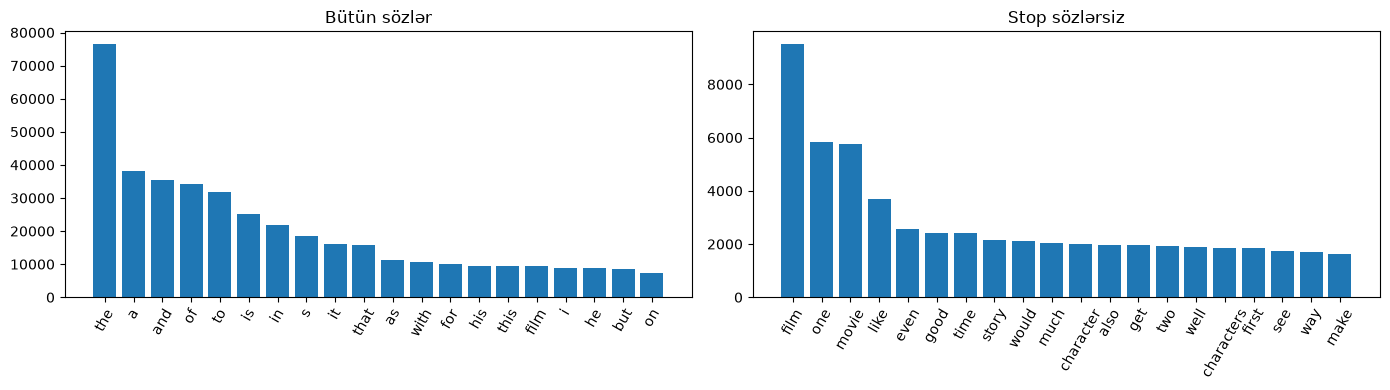

In [17]:
# 2.4. Korpusun statistikası: hansı sözlər ən çox işlənir?
# movie_reviews — IMDb-dən 2000 film rəyi (1000 müsbət, 1000 mənfi). Bölmə 5-də bu korpusla təsnifat edəcəyik.
from nltk.corpus import movie_reviews
from nltk import FreqDist

all_words = [w.lower() for w in movie_reviews.words() if w.isalpha()]
print("Korpusda söz sayı:", len(all_words), "| unikal sözlər:", len(set(all_words)))

fd_all = FreqDist(all_words)
fd_clean = FreqDist(w for w in all_words if w not in stop_en)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, fd, title in [(axes[0], fd_all, "Bütün sözlər"), (axes[1], fd_clean, "Stop sözlərsiz")]:
    words_, counts_ = zip(*fd.most_common(20))
    ax.bar(words_, counts_)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

🤔 **Sual:** Sol qrafikdə ən çox işlənən sözlər hansılardır? Onlardan rəyin müsbət və ya mənfi olduğunu anlamaq olarmı?
Bu, stop sözləri niyə silməyimizi yaxşı izah edir.

Bu müşahidə **Zipf qanunu** ilə bağlıdır: sözün tezliyi onun sıra nömrəsi ilə tərs mütənasibdir. Bir neçə söz çox tez-tez,
minlərlə söz isə cəmi bir-iki dəfə işlənir.

## 3. Aralıq təsvirlərin seçilməsi: mətni vektora necə çevirək?

Neyron şəbəkə və ya logistik reqressiya sözləri qəbul etmir — ona **ədəd vektoru** lazımdır.
Mətnin bu cür ədədi formasına **aralıq təsvir (intermediate representation)** deyilir.

Əsas variantlar (sadədən mürəkkəbə):

1. **One-hot** — hər söz uzunluğu lüğət ölçüsündə olan vektordur, bir yerdə 1, qalanları 0.
2. **Bag-of-Words (BoW, "sözlər kisəsi")** — mətn = hər sözün neçə dəfə işləndiyi vektor. Sözlərin sırası itir.
3. **TF-IDF** — BoW kimi, amma hər yerdə rast gəlinən sözlərin çəkisi azaldılır.
4. **Embedding (sıx vektorlar)** — hər söz 50–300 ölçülü "mənalı" vektordur. Mənaca yaxın sözlərin vektorları da yaxındır.

### 3.1. One-hot kodlaşdırma

In [18]:
sentence = "the cat sat on the mat".split()
vocab = sorted(set(sentence))
word2idx = {w: i for i, w in enumerate(vocab)}
print("Lüğət:", word2idx)

one_hot = np.eye(len(vocab), dtype=int)
for w in ["cat", "mat", "sat"]:
    print(f"{w:4s} → {one_hot[word2idx[w]]}")

# Problem: istənilən iki fərqli sözün skalyar hasili 0-dır — "cat" "mat"-a da, "dog"-a da eyni dərəcədə "uzaqdır".
print("cat · mat =", one_hot[word2idx["cat"]] @ one_hot[word2idx["mat"]])

Lüğət: {'cat': 0, 'mat': 1, 'on': 2, 'sat': 3, 'the': 4}
cat  → [1 0 0 0 0]
mat  → [0 1 0 0 0]
sat  → [0 0 0 1 0]
cat · mat = 0


One-hot-un problemləri:
- **Ölçü çox böyükdür:** lüğətdə 50 000 söz varsa, hər söz 50 000 ölçülü vektordur (demək olar ki, hamısı sıfır — *seyrək/sparse*).
- **Məna yoxdur:** `cat` və `dog` bir-birinə `cat` və `car` qədər "uzaqdır".

### 3.2. Bag-of-Words və TF-IDF

**TF-IDF** düsturu:

$$
\text{tfidf}(t, d) = \underbrace{\text{tf}(t, d)}_{\text{söz bu mətndə neçə dəfə}} \times \underbrace{\log\frac{N}{\text{df}(t)}}_{\text{söz nə qədər nadirdir}}
$$

- $N$ — mətnlərin sayı, $\text{df}(t)$ — $t$ sözü olan mətnlərin sayı.
- Söz bütün mətnlərdə varsa (*the*), $\log(N/N) = 0$ → çəkisi sıfırdır.
- Söz yalnız bir neçə mətndə varsa (*masterpiece*), çəkisi böyükdür.

In [19]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

docs = [
    "the movie was great and the actors were great",
    "the film was great",
    "the movie was terrible and boring",
    "I ate a great pizza",
]

bow = CountVectorizer()
X_bow = bow.fit_transform(docs)
display(pd.DataFrame(X_bow.toarray(), columns=bow.get_feature_names_out(), index=[f"d{i}" for i in range(len(docs))]))

tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(docs)
display(pd.DataFrame(X_tfidf.toarray().round(2), columns=tfidf.get_feature_names_out(), index=[f"d{i}" for i in range(len(docs))]))

,actors,and,ate,boring,film,great,movie,pizza,terrible,the,was,were
d0,1,1,0,0,0,2,1,0,0,2,1,1
d1,0,0,0,0,1,1,0,0,0,1,1,0
d2,0,1,0,1,0,0,1,0,1,1,1,0
d3,0,0,1,0,0,1,0,1,0,0,0,0


,actors,and,ate,boring,film,great,movie,pizza,terrible,the,was,were
d0,0.38,0.30,0.00,0.0,0.00,0.49,0.30,0.00,0.0,0.49,0.24,0.38
d1,0.00,0.00,0.00,0.0,0.67,0.43,0.00,0.00,0.0,0.43,0.43,0.00
d2,0.00,0.39,0.00,0.5,0.00,0.00,0.39,0.00,0.5,0.32,0.32,0.00
d3,0.00,0.00,0.64,0.0,0.00,0.41,0.00,0.64,0.0,0.00,0.00,0.00


İki vektorun nə qədər "oxşar" olduğunu **kosinus oxşarlığı** ilə ölçürük — vektorlar arasındakı bucağın kosinusu:

$$
\cos(\vec a, \vec b) = \frac{\vec a \cdot \vec b}{\|\vec a\| \, \|\vec b\|} \in [-1, 1]
$$

1 — eyni istiqamət (çox oxşar), 0 — əlaqə yoxdur, −1 — əks istiqamət.

In [20]:
sim = cosine_similarity(X_tfidf)
display(pd.DataFrame(sim.round(2), index=[f"d{i}" for i in range(4)], columns=[f"d{i}" for i in range(4)]))

,d0,d1,d2,d3
d0,1.00,0.52,0.47,0.20
d1,0.52,1.00,0.27,0.18
d2,0.47,0.27,1.00,0.00
d3,0.20,0.18,0.00,1.00


🤔 **Sual:** `d0` ("the movie was great...") ilə `d1` ("the film was great") mənaca demək olar ki, eynidir. Bəs `d3` ("I ate a great pizza") ilə?
TF-IDF-ə görə hansı cüt daha oxşardır? Niyə?

👉 TF-IDF bilmir ki, **movie** və **film** sinonimdir — onun üçün bunlar sadəcə iki fərqli sütundur.
Bu problemi həll etmək üçün sözün **mənasını** vektora "yerləşdirmək" lazımdır.

### 3.3. Embedding ideyası: "Sözü yoldaşından tanı"

**Distributiv hipotez** (J. R. Firth, 1957): *"You shall know a word by the company it keeps"* —
oxşar kontekstlərdə işlənən sözlərin mənası da oxşardır.

- *"I watched a great **movie** yesterday"*
- *"I watched a great **film** yesterday"*

`movie` və `film` eyni sözlərlə əhatə olunub → onların vektorları da yaxın olmalıdır.

**Embedding** — hər sözə uyğun gələn qısa (məsələn, 100 ölçülü) **sıx** vektor. Bu vektorlar əl ilə yox,
böyük korpus üzərində **öyrədilir** (Bölmə 4). PyTorch-da embedding sadəcə bir cədvəldir — `nn.Embedding`:

In [ ]:
print(f"""
        Lüğətin uzunluğu: {len(vocab)} söz
        Söz indeksləri: {word2idx}
        Lüğət: {vocab}""")

emb = nn.Embedding(num_embeddings=len(vocab), embedding_dim=4)   # 5 söz × 4 ölçü
print("Embedding cədvəli (hələ təsadüfi, öyrədilməyib):")
print(emb.weight.data)


ids = torch.tensor([word2idx[w] for w in "the cat sat".split()])
print("\nSöz indeksləri:", ids.tolist())
print("Vektorlar:\n", emb(ids))   # sadəcə cədvəldən uyğun sətirləri götürür


        Lüğətin uzunluğu: 5 söz
        Söz indeksləri: {'cat': 0, 'mat': 1, 'on': 2, 'sat': 3, 'the': 4}
        Lüğət: ['cat', 'mat', 'on', 'sat', 'the']
Embedding cədvəli (hələ təsadüfi, öyrədilməyib):
tensor([[-0.5596,  0.5335,  0.4069,  0.3946],
        [-1.2537,  0.9868, -0.4947, -1.2830],
        [ 0.4386, -0.0107,  1.3384, -0.2794],
        [ 0.2877, -0.0334, -1.0619, -0.1144],
        [ 0.1954, -0.7371,  1.7001,  0.3462]])

Söz indeksləri: [4, 0, 3]
Vektorlar:
 tensor([[ 0.1954, -0.7371,  1.7001,  0.3462],
        [-0.5596,  0.5335,  0.4069,  0.3946],
        [ 0.2877, -0.0334, -1.0619, -0.1144]], grad_fn=<EmbeddingBackward0>)


### 3.4. Hansı təsviri seçək?

| Təsvir | Ölçü | Mənanı tutur? | Sırası? | Nə vaxt seçmək |
|---|---|---|---|---|
| One-hot | lüğət ölçüsü | ❌ | ❌ | Kiçik lüğət, neyron şəbəkənin girişi (sonra embedding qatı) |
| BoW / TF-IDF | lüğət ölçüsü (seyrək) | ❌ | ❌ | Baseline, uzun mətnlərin təsnifatı, az resurs, izah edilə bilən model |
| Statik embedding (Word2Vec, GloVe) | 50–300 (sıx) | ✅ | ❌ (orta vektor) | Az etiketli data, qısa mətnlər, oxşarlıq/axtarış |
| Kontekstual embedding (BERT, GPT) | 768+ | ✅✅ (kontekstə görə) | ✅ | Ən yüksək keyfiyyət, GPU var |

Praktik qayda: **həmişə TF-IDF + logistik reqressiya ilə başlayın** (baseline), sonra mürəkkəb modellərin bu nəticəni nə qədər yaxşılaşdırdığını yoxlayın.

## 4. Aralıq təsvirlərin yaradılması: Word2Vec və GloVe

### 4.1. Word2Vec (Mikolov və b., Google, 2013)

Word2Vec-in ideyası çox sadədir: **sözü kontekstinə görə proqnozlaşdıran kiçik neyron şəbəkə öyrədək**.
Şəbəkənin öyrəndiyi çəkilər elə sözlərin vektorları olacaq.

İki variant var:

```
CBOW (Continuous Bag-of-Words):          Skip-gram:
kontekst → mərkəzi söz                    mərkəzi söz → kontekst

 the  ──┐                                          ┌──► the
 cat  ──┼──►  [ sat ]                    [ sat ] ──┼──► cat
 on   ──┤                                          ├──► on
 the  ──┘                                          └──► the
```

- **CBOW** — daha sürətli, tez-tez işlənən sözlər üçün yaxşıdır.
- **Skip-gram** — daha yavaş, amma nadir sözləri daha yaxşı öyrənir.

Pəncərə ölçüsü (`window=2`) — mərkəzi sözdən sola və sağa neçə söz kontekst sayılır.
Skip-gram üçün öyrətmə cütlərinin necə yarandığına baxaq:

In [22]:
def skipgram_pairs(tokens, window=2):
    pairs = []
    for i, center in enumerate(tokens):
        for j in range(max(0, i - window), min(len(tokens), i + window + 1)):
            if j != i:
                pairs.append((center, tokens[j]))
    return pairs


for center, context in skipgram_pairs("the quick brown fox jumps".split(), window=2):
    print(f"{center:6s} → {context}")

the    → quick
the    → brown
quick  → the
quick  → brown
quick  → fox
brown  → the
brown  → quick
brown  → fox
brown  → jumps
fox    → quick
fox    → brown
fox    → jumps
jumps  → brown
jumps  → fox


#### Word2Vec-i sıfırdan yazaq (kiçik nümunə)

Şəbəkənin quruluşu:

$$
\text{söz} \xrightarrow{\text{one-hot}} \underbrace{W_{in}}_{V \times d} \xrightarrow{\text{vektor } d} \underbrace{W_{out}}_{d \times V} \xrightarrow{\text{softmax}} P(\text{kontekst sözü})
$$

- $W_{in}$-in sətirləri — bizə lazım olan **söz vektorlarıdır**.
- Real Word2Vec-də lüğət böyük olduğundan (milyonlarla söz) tam softmax əvəzinə **negative sampling** istifadə olunur:
  hər düzgün cüt üçün bir neçə təsadüfi "yanlış" söz götürülür və model "düzgün cütü yanlışlardan ayırmağı" öyrənir.
  Bizim kiçik lüğətdə adi softmax kifayətdir.

Vektorların ölçüsünü **2** götürək ki, nəticəni birbaşa müstəvidə görə bilək.

In [ ]:
toy_corpus = [
    "king is a strong man", "queen is a wise woman", "man is strong", "woman is wise",
    "boy is a young man", "girl is a young woman", "prince is a young king", "princess is a young queen",
    "king rules the kingdom", "queen rules the kingdom", "man and woman", "boy and girl",
    "apple is a sweet fruit", "orange is a sweet fruit", "banana is a fruit", "i eat apple and orange",
    "i eat banana", "fruit is sweet",
]

toy_tokens = [s.split() for s in toy_corpus] # tokenlara ayırır
toy_vocab = sorted({w for s in toy_tokens for w in s}) # lüğət yaradır

t2i = {w: i for i, w in enumerate(toy_vocab)} # söz indeksləri yaradır
# nümunə
"""
söz indeksləri: {'apple': 0, 'banana': 1, 'boy': 2, 'eat': 3, 'fruit': 4, 'girl': 5, 'i': 6, 'is': 7, 'man': 8, 'orange': 9, 'princess': 10, 'prince': 11, 'queen': 12, 'rules': 13, 'strong': 14, 'the': 15, 'woman': 16, 'young': 17}
"""

pairs = [(t2i[c], t2i[o]) for s in toy_tokens for c, o in skipgram_pairs(s, window=2)] # öyrətmə cütləri yaradır
# nümunə
"""
[('king', 'is'), ('is', 'a'), ('a', 'strong'), ('strong', 'man'), ('queen', 'is'), ('is', 'a'), ('a', 'wise'), ('wise', 'woman'), ('man', 'is'), ('is', 'strong'), ('woman', 'is'), ('is', 'wise')]
"""
centers = torch.tensor([p[0] for p in pairs]) # mərkəzi söz indeksləri
contexts = torch.tensor([p[1] for p in pairs]) # kontekst söz indeksləri
print(f"Lüğət: {len(toy_vocab)} söz | öyrətmə cütləri: {len(pairs)}")

class SkipGram(nn.Module):
    def __init__(self, vocab_size, dim): # vocab_size: lüğətin uzunluğu, dim: vektorun ölçüsü
        super().__init__()
        self.w_in = nn.Embedding(vocab_size, dim)    # söz vektorları
        self.w_out = nn.Linear(dim, vocab_size)      # kontekst sözünü proqnozlaşdırır

    def forward(self, center_ids):
        return self.w_out(self.w_in(center_ids))     # logitlər (softmax CrossEntropy-nin içindədir)


torch.manual_seed(0) # təsadüfi sayıların təkrarlanmasını təmin edir
sg = SkipGram(len(toy_vocab), dim=2) # classın obyektini yaradıram

# sg.parameters() - classın parametrlərini götürür
# lr - learning rate - öyrənmə sürəti
opt = torch.optim.Adam(sg.parameters(), lr=0.05) # optimizator yaradıram

#region Işləmə məntiqi
"""
1. Loss funksiyasını hesablayırıq
2. Optimizatorun gradientlarını sıfırlayırıq, çünki gradientlar öncəki epochdan gəlir və əlavə olunur
3. Loss funksiyasını backward propagation ilə tərs istiqamətdə öyrədirik. Bu çox vacib bir məsələdir. Bundan qabaq
biz CNN keçəndə, back propagation nümünəsi şəklin bir neçə epoxada nə qədər yaxşılaşdığını görə bilərik.
4. Optimizatorun gradientlarını tərs istiqamətdə öyrədirik. 
"""
#endregion
for epoch in range(500):
    loss = F.cross_entropy(sg(centers), contexts)
    opt.zero_grad()
    loss.backward()
    opt.step()
    if epoch % 100 == 0:
        print(f"epoxa {epoch:3d}  loss={loss.item():.3f}")

Lüğət: ['a', 'and', 'apple', 'banana', 'boy', 'eat', 'fruit', 'girl', 'i', 'is', 'king', 'kingdom', 'man', 'orange', 'prince', 'princess', 'queen', 'rules', 'strong', 'sweet', 'the', 'wise', 'woman', 'young']
Lüğət: 24 söz | öyrətmə cütləri: 192
epoxa   0  loss=3.411
epoxa 100  loss=2.221
epoxa 200  loss=2.177
epoxa 300  loss=2.157
epoxa 400  loss=2.144


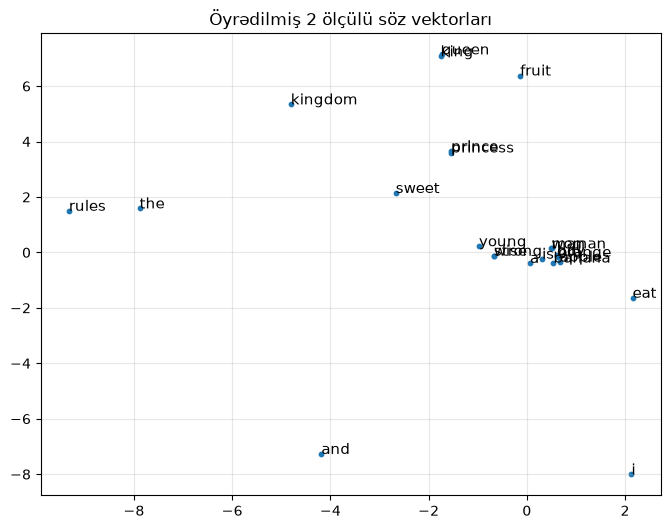

In [24]:
vecs = sg.w_in.weight.detach().numpy()
plt.figure(figsize=(8, 6))
plt.scatter(vecs[:, 0], vecs[:, 1], s=10)
for w, i in t2i.items():
    plt.annotate(w, vecs[i], fontsize=11)
plt.title("Öyrədilmiş 2 ölçülü söz vektorları")
plt.grid(alpha=0.3)
plt.show()

🤔 **Sual:** Qrafikdə `apple`, `orange`, `banana` bir-birinə yaxın yerləşibmi? Bəs `king`, `queen`, `prince`?
Biz şəbəkəyə heç vaxt "apple meyvədir" deməmişik — o, bunu yalnız **kontekstdən** öyrəndi.

#### Gensim ilə real Word2Vec

Praktikada Word2Vec-i özümüz yazmırıq — **gensim** kitabxanası bunu sürətli və optimallaşdırılmış şəkildə edir.
`movie_reviews` korpusundakı ~70 000 cümlə üzərində öyrədək.

Əsas parametrlər:
- `vector_size` — vektorun ölçüsü;
- `window` — kontekst pəncərəsi;
- `min_count` — bundan az işlənən sözlər atılır;
- `sg` — 1 = skip-gram, 0 = CBOW;
- `negative` — negative sampling üçün "yanlış" sözlərin sayı.

In [29]:
from gensim.models import Word2Vec

mr_sents = [[w.lower() for w in s if w.isalpha()] for s in movie_reviews.sents()]
mr_sents = [s for s in mr_sents if len(s) > 2]
print("Cümlələr:", len(mr_sents), "| nümunə:", mr_sents[0][:15])

t0 = time.time()
w2v = Word2Vec(sentences=mr_sents, vector_size=100, window=5, min_count=5,
               sg=1, negative=10, epochs=10, workers=4, seed=42)
print(f"Öyrədildi: {time.time() - t0:.1f} san | lüğət: {len(w2v.wv)} söz")

Cümlələr: 65105 | nümunə: ['plot', 'two', 'teen', 'couples', 'go', 'to', 'a', 'church', 'party', 'drink', 'and', 'then', 'drive']


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Öyrədildi: 17.7 san | lüğət: 14535 söz


In [32]:
for w in ["good", "bad", "funny", "actor", "horror", "boring"]:
    similar = ", ".join(f"{s} ({p:.2f})" for s, p in w2v.wv.most_similar(w, topn=6))
    print(f"{w:8s} → {similar}")

good     → decent (0.69), bad (0.68), great (0.66), darned (0.63), forte (0.63), gutsy (0.62)
bad      → good (0.68), lousy (0.64), crappy (0.63), cheesy (0.62), nope (0.61), corny (0.61)
funny    → clever (0.73), humorous (0.73), amusing (0.71), witty (0.71), suspenseful (0.69), wickedly (0.69)
actor    → performer (0.67), actors (0.66), gifted (0.66), mcdowell (0.66), offender (0.66), rapaport (0.65)
horror   → sci (0.75), fi (0.73), sf (0.69), fulci (0.69), slasher (0.69), commonly (0.69)
boring   → repetitive (0.78), unbelievably (0.75), tedious (0.75), dull (0.74), uninvolving (0.73), contrived (0.72)


In [33]:
print("similarity(movie, film)  =", round(float(w2v.wv.similarity("movie", "film")), 3))
print("similarity(movie, pizza) =", round(float(w2v.wv.similarity("movie", "pizza")), 3))
print("Hansı söz artıqdır? [actor, actress, director, banana] →",
      w2v.wv.doesnt_match(["actor", "actress", "director", "banana"]))

similarity(movie, film)  = 0.915
similarity(movie, pizza) = 0.443
Hansı söz artıqdır? [actor, actress, director, banana] → director


Bölmə 3-də TF-IDF `movie` və `film`-i tamamilə fərqli hesab edirdi. Word2Vec isə onların demək olar ki, sinonim olduğunu tapdı!

⚠️ Diqqət: `good` sözünə ən yaxın sözlər arasında çox vaxt `bad` da olur. Niyə? Çünki onlar **eyni kontekstlərdə** işlənir:
*"the movie was good"* / *"the movie was bad"*. Word2Vec "oxşar kontekst"i öyrənir, "eyni məna"nı yox — bu, rəy analizində problem yarada bilər.

### 4.2. GloVe (Global Vectors, Stanford, 2014)

Word2Vec mətni kiçik pəncərələrlə "gəzir" və hər dəfə lokal kontekstə baxır. **GloVe** isə əvvəlcə bütün korpus üzrə
**qlobal statistika** toplayır:

**1-ci addım — birgə rastgəlmə matrisi (co-occurrence matrix)** $X$: $X_{ij}$ — $j$ sözünün $i$ sözünün kontekstində neçə dəfə işləndiyi.

**2-ci addım — vektorları elə öyrədirik ki**, onların skalyar hasili bu sayın loqarifminə bərabər olsun:

$$
\vec w_i \cdot \vec{\tilde w}_j + b_i + \tilde b_j \approx \log X_{ij}
$$

İtki funksiyası:

$$
J = \sum_{i,j:\,X_{ij}>0} f(X_{ij}) \left( \vec w_i \cdot \vec{\tilde w}_j + b_i + \tilde b_j - \log X_{ij} \right)^2,
\qquad f(x) = \min\left(1, \left(\tfrac{x}{x_{max}}\right)^{0.75}\right)
$$

$f(x)$ — çəki funksiyasıdır: çox tez-tez rastlaşan cütlərin (*the, of*) təsirini məhdudlaşdırır, nadir cütlərin isə "səs-küyünü" azaldır.

Əvvəlcə kiçik korpusda birgə rastgəlmə matrisinin necə göründüyünə baxaq:

In [34]:
def cooccurrence(sentences, window=2):
    vocab_ = sorted({w for s in sentences for w in s})
    idx = {w: i for i, w in enumerate(vocab_)}
    X = np.zeros((len(vocab_), len(vocab_)))
    for s in sentences:
        for i, w in enumerate(s):
            for j in range(max(0, i - window), min(len(s), i + window + 1)):
                if i != j:
                    X[idx[w], idx[s[j]]] += 1.0 / abs(i - j)   # yaxın sözlər daha böyük çəki alır
    return pd.DataFrame(X, index=vocab_, columns=vocab_)


small = [s.split() for s in ["i like deep learning", "i like nlp", "i enjoy flying"]]
cooccurrence(small, window=1)

,deep,enjoy,flying,i,learning,like,nlp
deep,0.0,0.0,0.0,0.0,1.0,1.0,0.0
enjoy,0.0,0.0,1.0,1.0,0.0,0.0,0.0
flying,0.0,1.0,0.0,0.0,0.0,0.0,0.0
i,0.0,1.0,0.0,0.0,0.0,2.0,0.0
learning,1.0,0.0,0.0,0.0,0.0,0.0,0.0
like,1.0,0.0,0.0,2.0,0.0,0.0,1.0
nlp,0.0,0.0,0.0,0.0,0.0,1.0,0.0


#### Mini-GloVe-ni sıfırdan öyrədək

`movie_reviews` korpusunda ən çox işlənən 3000 söz üçün matrisi quraq və GloVe itkisini PyTorch-da minimallaşdıraq.

In [ ]:
V_GLOVE, WINDOW = 3000, 5
word_counts = Counter(w for s in mr_sents for w in s)
glove_vocab = [w for w, _ in word_counts.most_common(V_GLOVE)]
g2i = {w: i for i, w in enumerate(glove_vocab)}

# Birgə rastgəlmə matrisini numpy ilə sürətli hesablayırıq
X = np.zeros((V_GLOVE, V_GLOVE), dtype=np.float32)
for s in mr_sents:
    ids = np.array([g2i.get(w, -1) for w in s])
    for d in range(1, WINDOW + 1):
        a, b = ids[:-d], ids[d:]
        ok = (a >= 0) & (b >= 0)
        np.add.at(X, (a[ok], b[ok]), 1.0 / d)
        np.add.at(X, (b[ok], a[ok]), 1.0 / d)       # simmetrik
print("Matris:", X.shape, "| sıfırdan fərqli xanalar:", int((X > 0).sum()))

In [ ]:
class GloVe(nn.Module):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.w = nn.Embedding(vocab_size, dim)       # "mərkəzi" vektorlar
        self.w_ctx = nn.Embedding(vocab_size, dim)   # "kontekst" vektorları
        self.b = nn.Embedding(vocab_size, 1)
        self.b_ctx = nn.Embedding(vocab_size, 1)
        for e in [self.w, self.w_ctx]:
            nn.init.uniform_(e.weight, -0.5 / dim, 0.5 / dim)
        nn.init.zeros_(self.b.weight)
        nn.init.zeros_(self.b_ctx.weight)

    def forward(self, i, j):
        return (self.w(i) * self.w_ctx(j)).sum(1) + self.b(i).squeeze(1) + self.b_ctx(j).squeeze(1)


rows, cols = np.nonzero(X)
i_all = torch.tensor(rows, dtype=torch.long, device=device)
j_all = torch.tensor(cols, dtype=torch.long, device=device)
x_all = torch.tensor(X[rows, cols], device=device)
log_x = torch.log(x_all)
weight = torch.clamp((x_all / 100.0) ** 0.75, max=1.0)        # f(X_ij), x_max = 100

torch.manual_seed(0)
glove_model = GloVe(V_GLOVE, 50).to(device)
opt = torch.optim.Adagrad(glove_model.parameters(), lr=0.05)
BATCH = 65536
t0 = time.time()
for epoch in range(30):
    perm = torch.randperm(len(x_all), device=device)
    total = 0.0
    for k in range(0, len(perm), BATCH):
        idx = perm[k:k + BATCH]
        pred = glove_model(i_all[idx], j_all[idx])
        loss = (weight[idx] * (pred - log_x[idx]) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(idx)
    if epoch % 5 == 0 or epoch == 29:
        print(f"epoxa {epoch:2d}  J={total / len(perm):.4f}")
print(f"{time.time() - t0:.1f} san")

In [ ]:
# GloVe müəllifləri tövsiyə edir: son vektor = w + w_ctx
glove_vecs = (glove_model.w.weight + glove_model.w_ctx.weight).detach().cpu().numpy()
glove_norm = glove_vecs / np.linalg.norm(glove_vecs, axis=1, keepdims=True)


def mini_glove_similar(word, topn=6):
    sims = glove_norm @ glove_norm[g2i[word]]
    best = np.argsort(-sims)[1:topn + 1]
    return ", ".join(f"{glove_vocab[k]} ({sims[k]:.2f})" for k in best)


for w in ["good", "bad", "funny", "actor", "horror", "boring"]:
    print(f"{w:8s} → {mini_glove_similar(w)}")

Kiçik korpusda (1.5 mln söz) nəticə hələ "kobud"dur. Real GloVe vektorları **6 milyard** sözlük korpusda (Wikipedia + xəbərlər) öyrədilib.
Onları hazır şəkildə yükləyə bilərik (~66 MB):

In [36]:
import gensim.downloader as api

glove = api.load("glove-wiki-gigaword-50")     # 400 000 söz × 50 ölçü
print("Lüğət:", len(glove), "söz | vektorun ölçüsü:", glove.vector_size)

for w in ["good", "movie", "baku", "python"]:
    print(f"{w:7s} → {[s for s, _ in glove.most_similar(w, topn=7)]}")

Lüğət: 400000 söz | vektorun ölçüsü: 50
good    → ['better', 'really', 'always', 'sure', 'something', 'think', 'way']
movie   → ['movies', 'film', 'films', 'comedy', 'hollywood', 'drama', 'sequel']
baku    → ['tbilisi', 'azerbaijan', 'yerevan', 'azeri', 'minsk', 'ashgabat', 'azerbaijani']
python  → ['reticulated', 'spamalot', 'php', 'owl', 'mouse', 'reticulatus', 'perl']


#### Söz vektorları ilə "hesab"

Embedding-lərin ən məşhur xüsusiyyəti: vektorlar arasındakı **fərqlər mənalı münasibətləri** kodlayır.

$$
\vec{king} - \vec{man} + \vec{woman} \approx \vec{queen}
$$

"Kişi → qadın" istiqaməti vektor fəzasında təxminən sabitdir. Eyni ilə "ölkə → paytaxt", "feil → keçmiş zaman" və s.

In [37]:
def analogy(a, b, c, model=glove):
    # a : b = c : ?   →   b - a + c
    return model.most_similar(positive=[b, c], negative=[a], topn=3)


for a, b, c in [("man", "king", "woman"),
                ("france", "paris", "azerbaijan"),
                ("walk", "walked", "swim"),
                ("good", "better", "bad"),
                ("russia", "moscow", "japan")]:
    ans = ", ".join(f"{w} ({s:.2f})" for w, s in analogy(a, b, c))
    print(f"{a} : {b} = {c} : ?   →  {ans}")

man : king = woman : ?   →  queen (0.85), throne (0.77), prince (0.76)
france : paris = azerbaijan : ?   →  baku (0.88), vilnius (0.74), ashgabat (0.73)
walk : walked = swim : ?   →  swam (0.80), rowed (0.69), raced (0.68)
good : better = bad : ?   →  worse (0.90), too (0.83), unfortunately (0.82)
russia : moscow = japan : ?   →  tokyo (0.93), seoul (0.81), osaka (0.80)


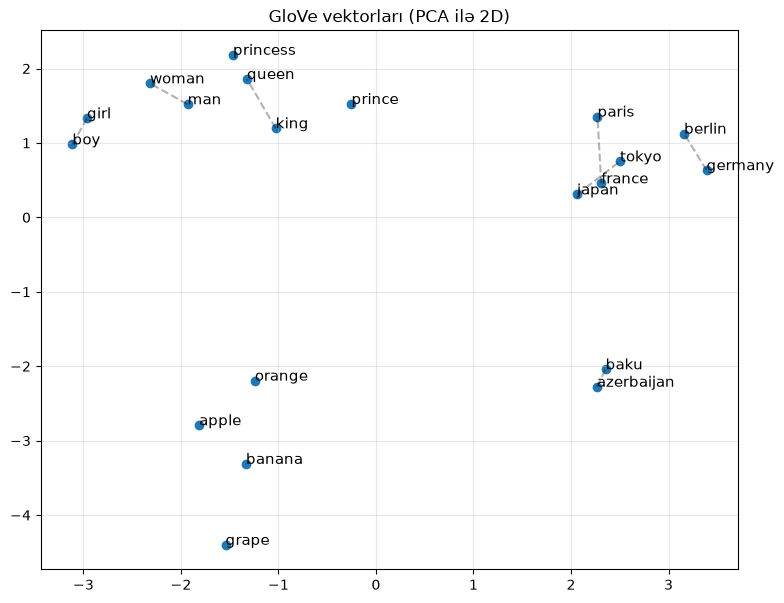

In [38]:
# Vektorları 2 ölçüyə endirib (PCA) vizuallaşdıraq
from sklearn.decomposition import PCA

words_vis = ["king", "queen", "man", "woman", "prince", "princess", "boy", "girl",
             "paris", "france", "berlin", "germany", "baku", "azerbaijan", "tokyo", "japan",
             "apple", "banana", "orange", "grape"]
P = PCA(n_components=2).fit_transform(np.array([glove[w] for w in words_vis]))

plt.figure(figsize=(9, 7))
plt.scatter(P[:, 0], P[:, 1])
for w, (x, y) in zip(words_vis, P):
    plt.annotate(w, (x, y), fontsize=11)
for a, b in [("man", "woman"), ("king", "queen"), ("boy", "girl"), ("france", "paris"),
             ("germany", "berlin"), ("azerbaijan", "baku"), ("japan", "tokyo")]:
    ia, ib = words_vis.index(a), words_vis.index(b)
    plt.plot(P[[ia, ib], 0], P[[ia, ib], 1], "k--", alpha=0.3)
plt.title("GloVe vektorları (PCA ilə 2D)")
plt.grid(alpha=0.3)
plt.show()

| | Word2Vec | GloVe |
|---|---|---|
| İdeya | Kontekstdən sözü proqnozlaşdıran neyron şəbəkə | Birgə rastgəlmə matrisinin faktorizasiyası |
| Statistika | Lokal (pəncərə-pəncərə) | Qlobal (bütün korpus birdən) |
| Öyrətmə | Onlayn, korpus böyüdükcə davam etmək olar | Əvvəlcə matris, sonra optimallaşdırma |
| Keyfiyyət | Praktikada oxşar | Praktikada oxşar |

**Hər ikisinin ümumi çatışmazlığı:** hər sözün **bir** vektoru var. *"bank of the river"* (çay sahili) və *"bank account"* (bank hesabı) — eyni vektor.
Bu problemi kontekstual modellər (BERT, GPT — Bölmə 7.3 və 9) həll edir.

## 5. Praktiki nümunə: Word2Vec ilə rəylərin təsnifatı

Tapşırıq: film rəyinin **müsbət** və ya **mənfi** olduğunu təyin etmək (`movie_reviews`, 2000 rəy).

Embedding-lər sözlər üçündür, bizə isə **bütün mətn** üçün vektor lazımdır. Ən sadə və çox effektiv üsul —
**rəydəki bütün söz vektorlarının ortalaması**:

$$
\vec{d} = \frac{1}{n}\sum_{k=1}^{n} \vec{w_k}
$$

Sonra bu vektoru adi təsnifatçıya (logistik reqressiya) veririk. 4 yanaşmanı müqayisə edək:
1. **TF-IDF** + logistik reqressiya (baseline);
2. **Öz Word2Vec**-imiz (yalnız train rəylərində öyrədilmiş) — orta vektor;
3. **Hazır GloVe** — orta vektor;
4. **Hazır GloVe** — TF-IDF çəkiləri ilə orta vektor (vacib sözlər daha çox təsir edir).

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

reviews, labels = [], []
for cat in movie_reviews.categories():          # 'neg', 'pos'
    for fid in movie_reviews.fileids(cat):
        reviews.append([w.lower() for w in movie_reviews.words(fid) if w.isalpha()])
        labels.append(1 if cat == "pos" else 0)
labels = np.array(labels)

tr_docs, te_docs, y_tr, y_te = train_test_split(reviews, labels, test_size=0.2,
                                                random_state=42, stratify=labels)
print("Train:", len(tr_docs), "| Test:", len(te_docs), "| Orta rəy uzunluğu:",
      int(np.mean([len(d) for d in reviews])), "söz")

results = {}

Train: 1600 | Test: 400 | Orta rəy uzunluğu: 664 söz


In [40]:
# 1) TF-IDF baseline
tfidf_vec = TfidfVectorizer(analyzer=lambda d: d, min_df=2, sublinear_tf=True)   # artıq tokenləşdirilib
Xtr_tfidf = tfidf_vec.fit_transform(tr_docs)
Xte_tfidf = tfidf_vec.transform(te_docs)

clf = LogisticRegression(C=10, max_iter=2000).fit(Xtr_tfidf, y_tr)
results["TF-IDF + LogReg"] = accuracy_score(y_te, clf.predict(Xte_tfidf))
print(results)

{'TF-IDF + LogReg': 0.8675}


In [41]:
def mean_vector(tokens, kv):
    vecs = [kv[w] for w in tokens if w in kv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(kv.vector_size)


def weighted_mean_vector(tokens, kv, idf):
    vecs, ws = [], []
    for w in tokens:
        if w in kv and w in idf:
            vecs.append(kv[w])
            ws.append(idf[w])
    return np.average(vecs, axis=0, weights=ws) if vecs else np.zeros(kv.vector_size)


def evaluate(name, Xtr, Xte):
    from sklearn.preprocessing import StandardScaler
    sc = StandardScaler().fit(Xtr)
    model = LogisticRegression(C=1.0, max_iter=2000).fit(sc.transform(Xtr), y_tr)
    results[name] = accuracy_score(y_te, model.predict(sc.transform(Xte)))
    print(f"{name:30s} accuracy = {results[name]:.3f}")


# 2) Öz Word2Vec-imiz: YALNIZ train rəylərində öyrədirik (test məlumatı sızmasın)
w2v_sup = Word2Vec(sentences=tr_docs, vector_size=100, window=5, min_count=3,
                   sg=1, negative=10, epochs=15, workers=4, seed=42)
evaluate("Word2Vec (öz) — orta",
         np.array([mean_vector(d, w2v_sup.wv) for d in tr_docs]),
         np.array([mean_vector(d, w2v_sup.wv) for d in te_docs]))

# 3) Hazır GloVe
evaluate("GloVe (hazır) — orta",
         np.array([mean_vector(d, glove) for d in tr_docs]),
         np.array([mean_vector(d, glove) for d in te_docs]))

# 4) Hazır GloVe + TF-IDF çəkiləri
idf = dict(zip(tfidf_vec.get_feature_names_out(), tfidf_vec.idf_))
evaluate("GloVe (hazır) — TF-IDF çəkili",
         np.array([weighted_mean_vector(d, glove, idf) for d in tr_docs]),
         np.array([weighted_mean_vector(d, glove, idf) for d in te_docs]))

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Word2Vec (öz) — orta           accuracy = 0.812
GloVe (hazır) — orta           accuracy = 0.708
GloVe (hazır) — TF-IDF çəkili  accuracy = 0.688


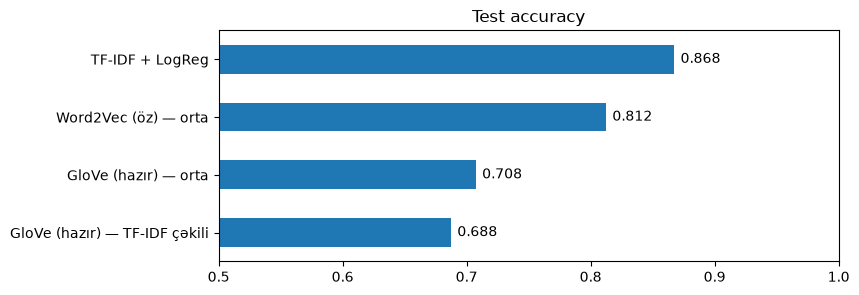

In [42]:
res = pd.Series(results).sort_values()
res.plot.barh(figsize=(8, 3), xlim=(0.5, 1.0), title="Test accuracy")
for k, v in enumerate(res):
    plt.text(v + 0.005, k, f"{v:.3f}", va="center")
plt.show()

🤔 **Müzakirə:** Nəticə ilk baxışdan təəccüblü ola bilər — sadə TF-IDF embedding-lərdən **yaxşı** işləyir! Niyə?

- Rəylər **uzundur** (~600 söz): TF-IDF-in kifayət qədər "siqnalı" var.
- Orta vektor götürəndə sözlərin sırası və vacib detallar "yuyulur": 600 sözün ortası əsasən neytral sözlərə yaxın olur.
- Word2Vec-də `good` və `bad` yaxındır (eyni kontekst!) — rəy analizi üçün bu pis xüsusiyyətdir.

**Embedding-lər nə vaxt qalib gəlir?**
- Mətnlər **qısadır** (tvitlər, axtarış sorğuları, sual başlıqları) — TF-IDF vektoru demək olar ki, boşdur.
- Etiketli data **azdır**, amma hazır embedding-lər böyük korpusdan "bilik" gətirir.
- Test mətnlərində train-də olmayan **sinonimlər** var.

Ən güclü nəticəni isə sözlərin **sırasını və kontekstini** nəzərə alan modellər verir — növbəti bölmələrin mövzusu.

## 6. Dil modelləri (Language Models)

**Dil modeli** — söz ardıcıllığına ehtimal verən modeldir: bu cümlə nə dərəcədə "təbiidir"?

- $P(\text{"I am going home"})$ — böyük;
- $P(\text{"home going am I"})$ — kiçik.

Ehtimalların zəncir qaydasına görə, bu, **növbəti sözü proqnozlaşdırmağa** gətirilir:

$$
P(w_1, w_2, \dots, w_n) = P(w_1)\cdot P(w_2 \mid w_1)\cdot P(w_3 \mid w_1, w_2) \cdots = \prod_{t=1}^{n} P(w_t \mid w_1, \dots, w_{t-1})
$$

Telefonunuzdakı klaviaturanın növbəti sözü təklif etməsi, ChatGPT/Claude-un cavab yazması — hamısı dil modelidir.
Fərq yalnız $P(w_t \mid \text{əvvəlki sözlər})$-i **necə** hesabladığımızdadır.

### 6.1. N-qram modeli — ən sadə dil modeli

Bütün tarixçəyə baxmaq çətindir, ona görə **Markov fərziyyəsi** edirik: növbəti söz yalnız son $n-1$ sözdən asılıdır.
**Biqram** ($n=2$) üçün:

$$
P(w_t \mid w_{t-1}) = \frac{\text{count}(w_{t-1}, w_t)}{\text{count}(w_{t-1})}
$$

Yəni sadəcə saymaq lazımdır!

In [43]:
lm_sents = mr_sents[:]
random.Random(42).shuffle(lm_sents)
lm_train, lm_test = lm_sents[:-3000], lm_sents[-3000:]

unigram = Counter()
bigram = defaultdict(Counter)
for s in lm_train:
    toks = ["<s>"] + s + ["</s>"]        # cümlənin başlanğıcı və sonu
    unigram.update(toks[1:])
    for a, b in zip(toks, toks[1:]):
        bigram[a][b] += 1

context_total = {a: sum(c.values()) for a, c in bigram.items()}
V_LM = len(unigram) + 1
print("Lüğət:", V_LM)

for w in ["the", "very", "special", "i"]:
    total = context_total[w]
    print(f"P(· | '{w}') →", [(nxt, round(c / total, 3)) for nxt, c in bigram[w].most_common(6)])

Lüğət: 38142
P(· | 'the') → [('film', 0.06), ('movie', 0.028), ('story', 0.013), ('most', 0.012), ('first', 0.012), ('same', 0.01)]
P(· | 'very') → [('good', 0.082), ('well', 0.064), ('little', 0.049), ('funny', 0.038), ('much', 0.028), ('very', 0.017)]
P(· | 'special') → [('effects', 0.677), ('edition', 0.036), ('</s>', 0.029), ('effect', 0.022), ('note', 0.016), ('and', 0.011)]
P(· | 'i') → [('m', 0.071), ('was', 0.058), ('ve', 0.044), ('can', 0.04), ('have', 0.038), ('don', 0.032)]


#### Mətn generasiyası

Dil modeli ilə mətn yaratmaq çox sadədir: `<s>`-dən başlayırıq, ehtimallara görə növbəti sözü **təsadüfi seçirik**, onu əlavə edirik, təkrarlayırıq.

In [44]:
def generate_bigram(max_len=25, seed=None):
    rng = random.Random(seed)
    word, out = "<s>", []
    for _ in range(max_len):
        nexts, counts = zip(*bigram[word].items())
        word = rng.choices(nexts, weights=counts)[0]
        if word == "</s>":
            break
        out.append(word)
    return " ".join(out)


for k in range(5):
    print("•", generate_bigram(seed=k))

• adding insult to think he has returned to come off post millennium
• when neither glorified extra class snooty accent rivals that it can see on their luck but the warring abilities
• heche whose name of ineptitude
• the chaos thrown into one of his prisoners decided to rattle you need i say that way there s delivery room
• the film s the audience


Hər iki qonşu söz "məntiqli" görünür, amma cümlə bütövlükdə mənasızdır — model yalnız **bir** əvvəlki sözü "xatırlayır".

#### Dil modelinin keyfiyyəti: Perplexity

**Perplexity** — model hər addımda orta hesabla neçə söz arasında "tərəddüd edir":

$$
\text{PPL} = \exp\left(-\frac{1}{N}\sum_{t=1}^{N} \log P(w_t \mid \text{kontekst})\right)
$$

Nə qədər **kiçikdirsə**, o qədər yaxşıdır. Test cümlələrində train-də görünməyən cütlər ola bilər ($P = 0$, $\log 0 = -\infty$!),
ona görə **hamarlaşdırma (smoothing)** edirik: hər saya kiçik $k$ əlavə edirik.

In [45]:
def p_unigram(w, k=0.1):
    return (unigram[w] + k) / (sum(unigram.values()) + k * V_LM)


def p_bigram(w, prev, k=0.01):
    return (bigram[prev][w] + k) / (context_total.get(prev, 0) + k * V_LM)


def perplexity(sentences, prob_fn):
    log_sum, n = 0.0, 0
    for s in sentences:
        toks = ["<s>"] + s + ["</s>"]
        for prev, w in zip(toks, toks[1:]):
            log_sum += math.log(prob_fn(w, prev))
            n += 1
    return math.exp(-log_sum / n)


print("Unigram perplexity:", round(perplexity(lm_test, lambda w, prev: p_unigram(w))))
print("Bigram  perplexity:", round(perplexity(lm_test, p_bigram)))
print("Təsadüfi model     :", V_LM, "(bütün sözlər eyni ehtimallı)")

Unigram perplexity: 1132
Bigram  perplexity: 701
Təsadüfi model     : 38142 (bütün sözlər eyni ehtimallı)


N-qram modellərinin problemləri:
- $n$ böyüdükcə əksər kombinasiyalar korpusda **heç vaxt** rast gəlinmir (məlumatın seyrəkliyi);
- uzun asılılıqları tuta bilmir: *"The **movies** that I watched with my friends last summer **were** great"* — `were`-in cəm olduğunu bilmək üçün 8 söz geriyə baxmaq lazımdır;
- sözlər arasında oxşarlıq yoxdur: `"great movie"` görmüşüksə, model `"great film"` haqqında heç nə bilmir.

Həll: $P(w_t \mid \text{kontekst})$-i **neyron şəbəkə** ilə hesablamaq. Şəbəkə embedding-lərdən istifadə edir və tarixçəni "yaddaşında" saxlayır.

## 7. Seq-to-seq alqoritmləri: RNN, LSTM, Transformer

Adi neyron şəbəkə (MLP) sabit ölçülü giriş gözləyir. Mətn isə **ardıcıllıqdır** və uzunluğu dəyişir.
Ardıcıllıqlarla işləyən əsas arxitekturalar:

```
RNN (1986)  →  LSTM (1997)  →  Seq2seq + Attention (2014)  →  Transformer (2017)  →  BERT, GPT, Claude
```

### 7.1. Kanonik rekurrent neyron şəbəkə (RNN)

RNN ardıcıllığı **söz-söz** oxuyur və **gizli vəziyyəti (hidden state)** $h_t$ — "yaddaşı" — yeniləyir:

$$
h_t = \tanh\left(W_{xh}\, x_t + W_{hh}\, h_{t-1} + b_h\right), \qquad y_t = W_{hy}\, h_t + b_y
$$

```
        y₁          y₂          y₃
        ↑           ↑           ↑
h₀ → [ RNN ] h₁ → [ RNN ] h₂ → [ RNN ] h₃
        ↑           ↑           ↑
        x₁          x₂          x₃
      "the"       "cat"       "sat"
```

Vacib: **bütün addımlarda eyni çəkilər** ($W_{xh}, W_{hh}$) istifadə olunur. Ona görə RNN istənilən uzunluqda ardıcıllığı emal edə bilir.

Gəlin RNN-i əl ilə yazıb, PyTorch-un `nn.RNN`-i ilə eyni nəticəni verdiyini yoxlayaq:

In [46]:
class MyRNN(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.W_xh = nn.Linear(input_size, hidden_size)
        self.W_hh = nn.Linear(hidden_size, hidden_size)

    def forward(self, x):                      # x: (batch, seq_len, input_size)
        h = torch.zeros(x.size(0), self.hidden_size)
        outputs = []
        for t in range(x.size(1)):             # ardıcıllığı addım-addım gəzirik
            h = torch.tanh(self.W_xh(x[:, t]) + self.W_hh(h))
            outputs.append(h)
        return torch.stack(outputs, dim=1), h


torch.manual_seed(0)
my_rnn = MyRNN(input_size=4, hidden_size=3)
torch_rnn = nn.RNN(input_size=4, hidden_size=3, batch_first=True)

# PyTorch-un RNN-inə bizim çəkiləri köçürürük
with torch.no_grad():
    torch_rnn.weight_ih_l0.copy_(my_rnn.W_xh.weight)
    torch_rnn.bias_ih_l0.copy_(my_rnn.W_xh.bias)
    torch_rnn.weight_hh_l0.copy_(my_rnn.W_hh.weight)
    torch_rnn.bias_hh_l0.copy_(my_rnn.W_hh.bias)

x = torch.randn(2, 5, 4)                       # 2 cümlə, hər biri 5 söz, hər söz 4 ölçülü vektor
out_my, h_my = my_rnn(x)
out_torch, h_torch = torch_rnn(x)
print("Çıxışın forması:", out_torch.shape, "  (batch, seq_len, hidden)")
print("Son gizli vəziyyət:", h_torch.shape, "  (num_layers, batch, hidden)")
print("Nəticələr eynidir?", torch.allclose(out_my, out_torch, atol=1e-6))

Çıxışın forması: torch.Size([2, 5, 3])   (batch, seq_len, hidden)
Son gizli vəziyyət: torch.Size([1, 2, 3])   (num_layers, batch, hidden)
Nəticələr eynidir? True


#### RNN-in əsas problemi: yox olan qradiyentlər (vanishing gradients)

Öyrətmə zamanı qradiyent zamanda **geriyə** yayılır (*Backpropagation Through Time*). Hər addımda o, $W_{hh}$-yə və $\tanh'$-ə vurulur.
Bu ədədlər 1-dən kiçikdirsə, 50 addımdan sonra qradiyent praktiki olaraq **sıfır** olur → RNN uzaq keçmişi "unudur".

Təcrübə: son çıxışın birinci, ikinci, ... girişlərə görə qradiyentinə baxaq.

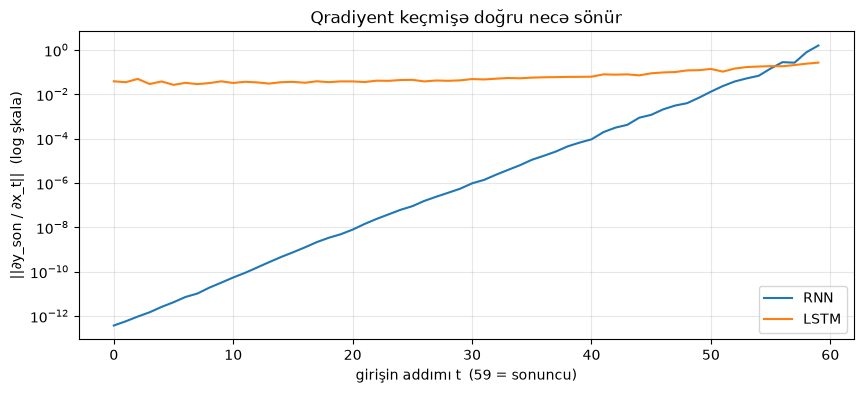

In [47]:
def grad_wrt_inputs(model, T=60, input_size=8, seed=0):
    torch.manual_seed(seed)
    x = torch.randn(1, T, input_size, requires_grad=True)
    out, _ = model(x)
    out[0, -1].sum().backward()                # son addımın çıxışı
    return x.grad[0].norm(dim=1).detach().numpy()   # hər addımdakı girişə görə qradiyentin normu


torch.manual_seed(0)
rnn_demo = nn.RNN(8, 64, batch_first=True)
lstm_demo = nn.LSTM(8, 64, batch_first=True)
with torch.no_grad():                          # praktikada tez-tez edilən hiylə: forget gate bias = 1
    lstm_demo.bias_ih_l0[64:128].fill_(1.0)
    lstm_demo.bias_hh_l0[64:128].fill_(1.0)

plt.figure(figsize=(10, 4))
plt.semilogy(grad_wrt_inputs(rnn_demo), label="RNN")
plt.semilogy(grad_wrt_inputs(lstm_demo), label="LSTM")
plt.xlabel("girişin addımı t  (59 = sonuncu)")
plt.ylabel("||∂y_son / ∂x_t||  (log şkala)")
plt.title("Qradiyent keçmişə doğru necə sönür")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Qrafikdə görünür ki, RNN-də qradiyent keçmişə doğru **eksponensial** sönür (log şkalada düz xətt).
LSTM-də isə qradiyent uzaq addımlara daha çox "çatır".

### 7.2. LSTM (Long Short-Term Memory)

LSTM bu problemi **qapılar (gates)** və ayrıca **hüceyrə vəziyyəti (cell state)** $c_t$ ilə həll edir.
$c_t$-ni "konveyer lenti" kimi təsəvvür edin: məlumat onun üzərində demək olar ki, dəyişmədən uzun müddət daşına bilər.

$$
\begin{aligned}
f_t &= \sigma(W_f [h_{t-1}, x_t] + b_f) && \text{unutma qapısı: köhnə yaddaşın nə qədəri qalsın?} \\
i_t &= \sigma(W_i [h_{t-1}, x_t] + b_i) && \text{giriş qapısı: yeni məlumatın nə qədəri yazılsın?} \\
\tilde c_t &= \tanh(W_c [h_{t-1}, x_t] + b_c) && \text{yeni "namizəd" məlumat} \\
c_t &= f_t \odot c_{t-1} + i_t \odot \tilde c_t && \text{yaddaşın yenilənməsi} \\
o_t &= \sigma(W_o [h_{t-1}, x_t] + b_o) && \text{çıxış qapısı: yaddaşdan nəyi göstərək?} \\
h_t &= o_t \odot \tanh(c_t)
\end{aligned}
$$

- $\sigma$ (sigmoid) 0 ilə 1 arasında qiymət verir — "kran" kimi: 0 = bağla, 1 = tam aç.
- $\odot$ — elementbəelement vurma.
- Əsas hiylə: $c_t = f_t \odot c_{t-1} + \dots$ — **toplama**. $f_t \approx 1$ olduqda qradiyent $c_t$ boyunca sönmədən keçir.

Nümunə: *"**Anar** Bakıda doğulub. ... (çox sözlər) ... **O** proqramçıdır."* — LSTM "subyekt = Anar, kişi" məlumatını
unutma qapısını açıq saxlayaraq uzun müddət daşıya bilər.

LSTM-i də əl ilə yazıb `nn.LSTM` ilə yoxlayaq:

In [48]:
def my_lstm_step(x_t, h, c, lstm):
    # PyTorch çəkiləri [i, f, g, o] ardıcıllığı ilə bir matrisdə saxlayır
    gates = x_t @ lstm.weight_ih_l0.T + lstm.bias_ih_l0 + h @ lstm.weight_hh_l0.T + lstm.bias_hh_l0
    i, f, g, o = gates.chunk(4, dim=1)
    i, f, g, o = torch.sigmoid(i), torch.sigmoid(f), torch.tanh(g), torch.sigmoid(o)
    c = f * c + i * g
    h = o * torch.tanh(c)
    return h, c


torch.manual_seed(0)
lstm = nn.LSTM(input_size=4, hidden_size=3, batch_first=True)
x = torch.randn(2, 5, 4)
h = torch.zeros(2, 3)
c = torch.zeros(2, 3)
for t in range(x.size(1)):
    h, c = my_lstm_step(x[:, t], h, c, lstm)

out, (h_n, c_n) = lstm(x)
print("nn.LSTM qaytarır: output", tuple(out.shape), "| h_n", tuple(h_n.shape), "| c_n", tuple(c_n.shape))
print("Əl ilə yazılmış LSTM eyni nəticəni verir?", torch.allclose(h, h_n[0], atol=1e-6), torch.allclose(c, c_n[0], atol=1e-6))
print("Parametrlərin sayı: RNN =", sum(p.numel() for p in nn.RNN(4, 3).parameters()),
      "| LSTM =", sum(p.numel() for p in lstm.parameters()), "(4 dəfə çox — 4 qapı)")

nn.LSTM qaytarır: output (2, 5, 3) | h_n (1, 2, 3) | c_n (1, 2, 3)
Əl ilə yazılmış LSTM eyni nəticəni verir? True True
Parametrlərin sayı: RNN = 27 | LSTM = 108 (4 dəfə çox — 4 qapı)


#### Seq2seq: Encoder–Decoder arxitekturası

Tərcümə kimi tapşırıqlarda giriş və çıxış ardıcıllıqlarının uzunluğu fərqlidir. **Seq2seq** (Sutskever və b., 2014) iki RNN/LSTM-dən ibarətdir:

```
            ENCODER (girişi oxuyur)                    DECODER (çıxışı yazır)
"Mən" → [LSTM] → "evə" → [LSTM] → "gedirəm" → [LSTM] ══ h ══► [LSTM] → "I" → [LSTM] → "am" → [LSTM] → "going" → ...
                                                  "kontekst vektoru"
```

1. **Encoder** bütün giriş cümləsini oxuyur və onu bir vektora — **kontekst vektoruna** sıxır.
2. **Decoder** bu vektordan başlayaraq çıxış cümləsini söz-söz generasiya edir (dil modeli kimi!).

Problem: uzun cümlənin bütün mənasını **bir** vektora sıxmaq çətindir — "darboğaz" (bottleneck).
Həll: **Attention (diqqət)** mexanizmi — decoder hər addımda encoder-in **bütün** gizli vəziyyətlərinə baxa bilir və hansının vacib olduğuna özü qərar verir.

### 7.3. Transformer — "Attention Is All You Need" (2017)

Transformer-in müəllifləri bir addım da irəli getdilər: **rekurrensiyanı tamamilə atdılar**, yalnız attention saxladılar.

**RNN-in problemləri:**
- ardıcıl işləyir (addım $t$ addım $t-1$-i gözləyir) → GPU-da paralelləşdirmək olmur, yavaşdır;
- uzaq sözlər arasında məlumat çox addımdan keçməlidir.

**Transformer-də** hər söz bir addımda **bütün** digər sözlərə "baxır" → paralel işləyir və uzaq asılılıqları asanlıqla tutur.

#### Self-attention (özünə diqqət)

Hər söz üçün 3 vektor hesablanır:
- **Query (Q, sorğu)** — "mən nə axtarıram?"
- **Key (K, açar)** — "məndə nə var?"
- **Value (V, dəyər)** — "məni seçsələr, hansı məlumatı verəcəyəm?"

$$
\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V
$$

Analogiya — kitabxana: siz **sorğu** ilə gəlirsiniz, onu kitabların **açar sözləri** ilə müqayisə edirsiniz, uyğun kitabların **məzmununu** götürürsünüz.
$\sqrt{d_k}$-ya bölmə — skalyar hasillər çox böyüyüb softmax-ı "doydurmasın" deyə.

In [49]:
def attention(Q, K, V, mask=None):
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)      # hər söz cütü üçün "uyğunluq"
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))
    weights = torch.softmax(scores, dim=-1)                 # hər sətrin cəmi = 1
    return weights @ V, weights


tokens = ["the", "animal", "didn't", "cross", "the", "street", "because", "it", "was", "tired"]
torch.manual_seed(0)
d_model = 16
x = torch.randn(len(tokens), d_model)          # söz embedding-ləri (burada təsadüfi)
W_q, W_k, W_v = (nn.Linear(d_model, d_model, bias=False) for _ in range(3))

out, w = attention(W_q(x), W_k(x), W_v(x))
print("Giriş:", tuple(x.shape), "→ Çıxış:", tuple(out.shape), "— hər söz üçün yeni, kontekstli vektor")

# PyTorch-un hazır funksiyası ilə yoxlama
ref = F.scaled_dot_product_attention(W_q(x)[None], W_k(x)[None], W_v(x)[None])[0]
print("F.scaled_dot_product_attention ilə eynidir?", torch.allclose(out, ref, atol=1e-5))

Giriş: (10, 16) → Çıxış: (10, 16) — hər söz üçün yeni, kontekstli vektor
F.scaled_dot_product_attention ilə eynidir? True


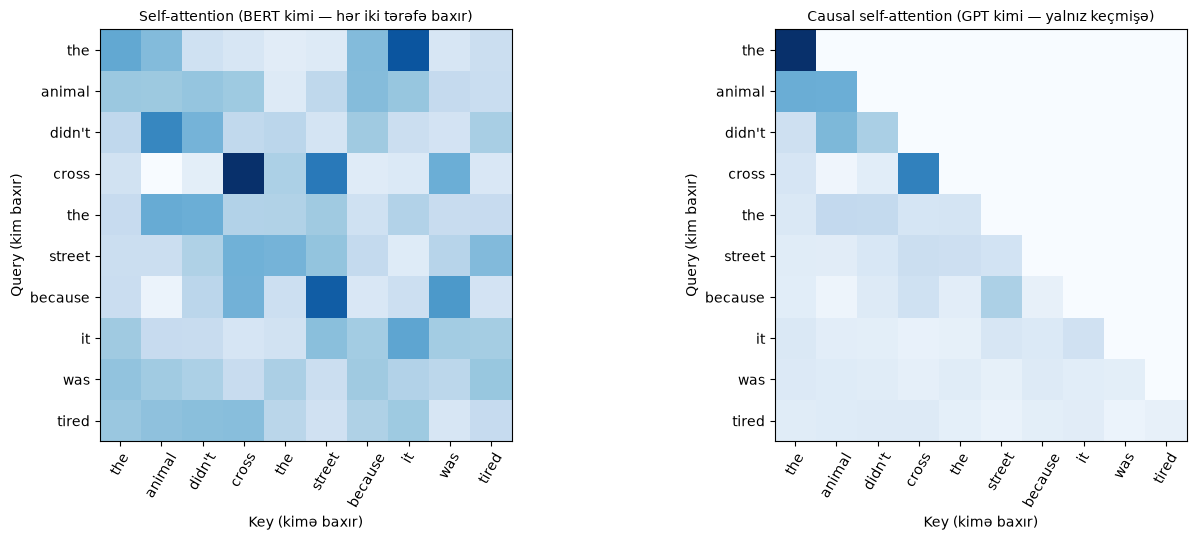

In [50]:
# Dil modeli üçün söz "gələcəyə" baxmamalıdır: səbəbiyyət maskası (causal mask)
causal_mask = torch.tril(torch.ones(len(tokens), len(tokens)))
_, w_causal = attention(W_q(x), W_k(x), W_v(x), mask=causal_mask)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, ww, title in [(axes[0], w, "Self-attention (BERT kimi — hər iki tərəfə baxır)"),
                      (axes[1], w_causal, "Causal self-attention (GPT kimi — yalnız keçmişə)")]:
    im = ax.imshow(ww.detach(), cmap="Blues")
    ax.set_xticks(range(len(tokens)), tokens, rotation=60)
    ax.set_yticks(range(len(tokens)), tokens)
    ax.set_xlabel("Key (kimə baxır)")
    ax.set_ylabel("Query (kim baxır)")
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

Çəkilər hələ təsadüfidir, ona görə xəritədə məna yoxdur. Öyrədilmiş modeldə isə, məsələn, `it` sözü `animal`-a güclü "baxır" —
model `it`-in kimə aid olduğunu başa düşür.

#### Mövqe kodlaşdırması (positional encoding)

Attention sözlərin **sırasını bilmir**: *"dog bites man"* və *"man bites dog"* onun üçün eynidir!
Ona görə hər söz vektoruna onun **mövqeyini** bildirən vektor əlavə edilir. Orijinal məqalədə — sinus və kosinuslar:

$$
PE_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{2i/d}}\right), \qquad PE_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{2i/d}}\right)
$$

In [ ]:
def positional_encoding(max_len, d):
    pos = torch.arange(max_len).unsqueeze(1)
    div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
    pe = torch.zeros(max_len, d)
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe


pe = positional_encoding(100, 64)
plt.figure(figsize=(12, 4))
plt.imshow(pe.T, aspect="auto", cmap="RdBu")
plt.xlabel("mövqe (sözün yeri)")
plt.ylabel("vektorun ölçüsü")
plt.colorbar()
plt.title("Sinusoidal positional encoding: hər mövqenin unikal 'barkodu' var")
plt.show()

#### Transformer bloku

Bir Transformer qatı:

```
x ──► Multi-Head Self-Attention ──► (+x) ──► LayerNorm ──► Feed-Forward (MLP) ──► (+) ──► LayerNorm ──► çıxış
 └────────── residual ─────────────┘                    └──────── residual ─────┘
```

- **Multi-head** — attention bir neçə dəfə paralel hesablanır (məs. 8 "baş"); hər baş fərqli münasibəti öyrənir (biri qrammatikanı, biri əvəzlikləri...).
- **Residual əlaqələr və LayerNorm** — Modul 5-dəki ResNet və normalizasiya ideyaları; dərin şəbəkənin öyrənməsini asanlaşdırır.
- **Encoder** (BERT) — hər iki tərəfə baxır, mətni "anlamaq" üçün; **Decoder** (GPT, Claude) — causal mask ilə, mətn generasiyası üçün.

PyTorch-da hazır bloklar var:

In [52]:
layer = nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=128, batch_first=True)
encoder = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False)

x = torch.randn(3, 12, 64)                     # 3 cümlə × 12 token × 64 ölçü
mask = nn.Transformer.generate_square_subsequent_mask(12)
print("Causal mask (0 = baxmaq olar, -inf = qadağandır):\n", mask[:5, :5])
print("\nÇıxış:", tuple(encoder(x, mask=mask, is_causal=True).shape))
print("Parametrlər:", sum(p.numel() for p in encoder.parameters()))

Causal mask (0 = baxmaq olar, -inf = qadağandır):
 tensor([[0., -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0.]])

Çıxış: (3, 12, 64)
Parametrlər: 66944


| | RNN | LSTM | Transformer |
|---|---|---|---|
| Ardıcıllığı necə emal edir | Addım-addım | Addım-addım | Hamısı birdən (paralel) |
| Uzun asılılıqlar | ❌ Zəif | ✅ Yaxşı (yüzlərlə addım) | ✅✅ Çox yaxşı (min-lərlə token) |
| GPU-da sürət | Yavaş | Yavaş | Sürətli |
| Yaddaş tələbi | Az | Az | Uzunluğun kvadratı ilə artır |
| Harada istifadə olunur | Tədris, sadə tapşırıqlar | Zaman sıraları, kiçik modellər | Bütün müasir dil modelləri |

## 8. Praktiki nümunə: simvol səviyyəli RNN ilə ad generasiyası

[PyTorch tutorial-ına](https://pytorch.org/tutorials/intermediate/char_rnn_generation_tutorial.html) əsaslanan tapşırıq:
18 dildə ~20 000 soyad var. Model **dil** (məs. *Russian*) və **ilk hərf** verildikdə həmin dilə uyğun "yeni" soyad generasiya etməlidir.

Bu, Bölmə 6-dakı dil modelinin eynisidir, sadəcə:
- sözlər əvəzinə **simvollar** (hərflər) istifadə edirik;
- n-qram əvəzinə **RNN / LSTM / Transformer** hərflərin ehtimalını hesablayır;
- model həm də **kateqoriyanı** (dili) bilir — buna *şərti dil modeli (conditional LM)* deyilir.

```
Giriş:   [Russian] + "K" "o" "v" "a" "l" "e" "v"
Hədəf:              "o" "v" "a" "l" "e" "v" <EOS>
```

Hər addımda model növbəti hərfi proqnozlaşdırır; `<EOS>` (*end of sequence*) — "ad bitdi" deməkdir.

In [53]:
import os, glob, zipfile, unicodedata, urllib.request

if not os.path.exists("data/names"):
    urllib.request.urlretrieve("https://download.pytorch.org/tutorial/data.zip", "data.zip")
    zipfile.ZipFile("data.zip").extractall(".")

all_letters = string.ascii_letters + " .,;'-"
n_letters = len(all_letters) + 1               # +1 — <EOS> simvolu
EOS = n_letters - 1
letter2idx = {ch: i for i, ch in enumerate(all_letters)}


def unicode_to_ascii(s):
    # "Ślusàrski" → "Slusarski": diakritik işarələri atırıq
    return "".join(c for c in unicodedata.normalize("NFD", s)
                   if unicodedata.category(c) != "Mn" and c in all_letters)


category_lines = {}
for path in sorted(glob.glob("data/names/*.txt")):
    category = os.path.splitext(os.path.basename(path))[0]
    lines = [unicode_to_ascii(line.strip()) for line in open(path, encoding="utf-8")]
    category_lines[category] = sorted({l for l in lines if len(l) > 1})
all_categories = list(category_lines)
n_categories = len(all_categories)

print("Dillər:", n_categories)
display(pd.DataFrame({"say": {c: len(v) for c, v in category_lines.items()},
                      "nümunə": {c: ", ".join(random.sample(v, 4)) for c, v in category_lines.items()}}))

Dillər: 18


,say,nümunə
Arabic,108,"Awad, Amari, Shammas, Ganim"
Chinese,246,"Hiu, Gwock, Dong, Tong"
Czech,502,"Chromy, Pudel, Schwartz, Tykal"
Dutch,286,"Veen, Daele, Ryskamp, Althuis"
English,3668,"Appleyard, Burnett, Ellison, Espley"
French,273,"Tolbert, Beaumont, Firmin, Proulx"
German,690,"Hafner, Porsche, Teufel, Jollenbeck"
Greek,193,"Adamou, Dertilis, Tourna, Lillis"
Irish,226,"Lennon, Finnegan, Connolly, Donndubhan"
Italian,701,"Gimondi, Altamura, Alessi, Maestri"


Diqqət: *Russian* dilində ~9 000 ad var, *Vietnamese* dilində isə cəmi ~70. Tutorial-dakı kimi öyrətmə zamanı əvvəlcə dili **bərabər ehtimalla**,
sonra həmin dildən təsadüfi ad seçirik — yoxsa model yalnız rus soyadlarını öyrənərdi.

Tutorial-dan bir fərqimiz var: sürət üçün adları bir-bir yox, **batch**-lərlə (64 ad birdən) emal edirik.
Fərqli uzunluqlu adları eyni uzunluğa **padding** ilə gətiririk, padding mövqelərini isə itki hesablanarkən nəzərə almırıq (`ignore_index=-100`).

In [54]:
from torch.nn.utils.rnn import pad_sequence


def random_batch(batch_size=64):
    cats, inputs, targets = [], [], []
    for _ in range(batch_size):
        cat = random.randrange(n_categories)
        name = random.choice(category_lines[all_categories[cat]])
        ids = [letter2idx[ch] for ch in name]
        cats.append(cat)
        inputs.append(torch.tensor(ids))                 # K o v a l e v
        targets.append(torch.tensor(ids[1:] + [EOS]))    # o v a l e v <EOS>
    return (torch.tensor(cats),
            pad_sequence(inputs, batch_first=True, padding_value=EOS),
            pad_sequence(targets, batch_first=True, padding_value=-100))


c, xb, yb = random_batch(3)
print("Kateqoriyalar:", [all_categories[i] for i in c])
print("Giriş :\n", xb)
print("Hədəf :\n", yb)

Kateqoriyalar: ['German', 'Irish', 'Czech']
Giriş :
 tensor([[51,  4, 11, 11, 22,  4,  6,  4, 17],
        [41,  7,  0, 17, 11,  0,  8, 13, 58],
        [41,  0, 21, 11,  8,  2, 10,  0, 58]])
Hədəf :
 tensor([[   4,   11,   11,   22,    4,    6,    4,   17,   58],
        [   7,    0,   17,   11,    0,    8,   13,   58, -100],
        [   0,   21,   11,    8,    2,   10,    0,   58, -100]])


### 8.1. Modellər

Tutorial-da hərflər one-hot vektor kimi verilir. Biz bunun əvəzinə `nn.Embedding` istifadə edirik — riyazi olaraq eynidir
(one-hot × matris = matrisin bir sətri), sadəcə daha səmərəlidir.

Hər addımda girişə **hərfin vektoru + dilin vektoru** verilir. Eyni interfeysli 3 model yazaq: RNN, LSTM, Transformer.

In [55]:
class RNNNameGenerator(nn.Module):
    def __init__(self, cell="lstm", hidden=128, emb=32, cat_emb=16):
        super().__init__()
        self.char_emb = nn.Embedding(n_letters, emb)
        self.cat_emb = nn.Embedding(n_categories, cat_emb)
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM}[cell]
        self.rnn = rnn_cls(emb + cat_emb, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.1)
        self.out = nn.Linear(hidden, n_letters)

    def forward(self, chars, cats):                         # chars: (B, T), cats: (B,)
        x = self.char_emb(chars)                            # (B, T, emb)
        c = self.cat_emb(cats)[:, None, :].expand(-1, x.size(1), -1)   # dil vektoru hər addıma
        h, _ = self.rnn(torch.cat([x, c], dim=2))           # (B, T, hidden)
        return self.out(self.dropout(h))                    # (B, T, n_letters) — növbəti hərfin logitləri


class TransformerNameGenerator(nn.Module):
    def __init__(self, d=64, heads=4, layers=2, max_len=32):
        super().__init__()
        self.char_emb = nn.Embedding(n_letters, d)
        self.cat_emb = nn.Embedding(n_categories, d)
        self.pos_emb = nn.Embedding(max_len, d)             # öyrədilən mövqe vektorları (GPT kimi)
        layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=4 * d, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.out = nn.Linear(d, n_letters)

    def forward(self, chars, cats):
        T = chars.size(1)
        pos = torch.arange(T, device=chars.device)
        x = self.char_emb(chars) + self.cat_emb(cats)[:, None, :] + self.pos_emb(pos)
        mask = nn.Transformer.generate_square_subsequent_mask(T, device=chars.device)
        return self.out(self.encoder(x, mask=mask, is_causal=True))   # causal: gələcək hərflərə baxmır


for m in [RNNNameGenerator("rnn"), RNNNameGenerator("lstm"), TransformerNameGenerator()]:
    print(f"{m.__class__.__name__:25s} {getattr(m, 'rnn', m).__class__.__name__:20s} "
          f"parametrlər: {sum(p.numel() for p in m.parameters()):,}")

RNNNameGenerator          RNN                  parametrlər: 32,571
RNNNameGenerator          LSTM                 parametrlər: 100,923
TransformerNameGenerator  TransformerNameGenerator parametrlər: 110,779


### 8.2. Öyrətmə

İtki — hər addımda növbəti hərfin **cross-entropy**-si (Modul 5-dəki çoxsinifli təsnifatın eynisi, sadəcə "siniflər" = hərflər).

In [56]:
N_STEPS = 4000        # vaxtınız azdırsa, azaldın


def train_generator(model, n_steps=N_STEPS, lr=3e-3, batch_size=64, log_every=250):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, n_steps)
    history, running = [], 0.0
    model.train()
    t0 = time.time()
    for step in range(1, n_steps + 1):
        cats, x, y = (t.to(device) for t in random_batch(batch_size))
        logits = model(x, cats)
        loss = F.cross_entropy(logits.reshape(-1, n_letters), y.reshape(-1), ignore_index=-100)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # qradiyentin "partlamasından" qoruyur
        opt.step()
        sched.step()
        running += loss.item()
        if step % log_every == 0:
            history.append(running / log_every)
            running = 0.0
    print(f"{model.__class__.__name__}: son loss = {history[-1]:.3f}, vaxt = {time.time() - t0:.0f} san")
    return history


torch.manual_seed(42)
random.seed(42)
generators = {
    "RNN": RNNNameGenerator("rnn"),
    "LSTM": RNNNameGenerator("lstm"),
    "Transformer": TransformerNameGenerator(),
}
histories = {name: train_generator(m) for name, m in generators.items()}

RNNNameGenerator: son loss = 1.417, vaxt = 14 san
RNNNameGenerator: son loss = 1.098, vaxt = 29 san
TransformerNameGenerator: son loss = 1.225, vaxt = 52 san


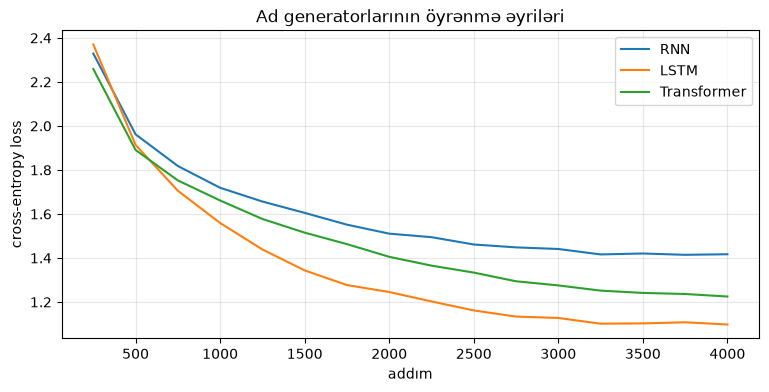

In [57]:
plt.figure(figsize=(9, 4))
for name, h in histories.items():
    plt.plot(np.arange(1, len(h) + 1) * 250, h, label=name)
plt.xlabel("addım")
plt.ylabel("cross-entropy loss")
plt.title("Ad generatorlarının öyrənmə əyriləri")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 8.3. Generasiya (sampling)

Bölmə 6-dakı kimi: başlanğıc hərfdən başlayırıq, model növbəti hərfin ehtimallarını verir, birini seçirik, əlavə edirik, təkrarlayırıq — `<EOS>` gələnə qədər.

**Temperatur** $\tau$ — "yaradıcılıq" dərəcəsi: $\text{softmax}(\text{logits} / \tau)$
- $\tau \to 0$ — həmişə ən ehtimallı hərf (darıxdırıcı, təkrarlanan adlar);
- $\tau = 1$ — modelin öz ehtimalları;
- $\tau > 1$ — daha təsadüfi (yaradıcı, amma tez-tez mənasız).

In [58]:
@torch.no_grad()
def generate_name(model, category, start="A", temperature=0.8, max_len=20):
    model.eval()
    cat = torch.tensor([all_categories.index(category)], device=device)
    name = start
    for _ in range(max_len):
        x = torch.tensor([[letter2idx[ch] for ch in name]], device=device)
        logits = model(x, cat)[0, -1] / temperature        # son hərfdən sonrakı hərfin logitləri
        idx = torch.multinomial(torch.softmax(logits, dim=0), 1).item()
        if idx == EOS:
            break
        name += all_letters[idx]
    return name


torch.manual_seed(1)
rows = []
for category, letters in [("Russian", "RUS"), ("German", "GER"), ("Spanish", "SPA"),
                          ("Chinese", "CHI"), ("Japanese", "JAP"), ("Irish", "IRI")]:
    for name, model in generators.items():
        rows.append({"dil": category, "model": name,
                     "adlar": ", ".join(generate_name(model, category, ch) for ch in letters)})
pd.DataFrame(rows).pivot(index="dil", columns="model", values="adlar")

model,LSTM,RNN,Transformer
dil,,,
Chinese,"Cheng, Hui, Ing","Chi, Hui, Iwo","Chian, Huang, Ing"
German,"Gerbers, Eumann, Roser","Gesher, Esser, Roses","Gross, Elchert, Reitzer"
Irish,"Ivis, Roaidh, Ivon","Ielh, Rodam, Icel","Ivor, Ronall, Ivor"
Japanese,"Jono, Arakata, Pate","Janaemashi, Atoo, Perohaka","Jusukara, Ahamaka, Pakaosu"
Russian,"Rotchinsky, Utsalihanov, Shanovsky","Rovamukov, Ushelov, Shelkov","Rubalmov, Ushuz, Shitin"
Spanish,"Silva, Puren, Arevoro","Stavollan, Proves, Alamilo","Silvan, Pina, Abell"


In [59]:
# Temperaturun təsiri
torch.manual_seed(0)
for t in [0.2, 0.8, 1.5]:
    names = [generate_name(generators["LSTM"], "Italian", ch, temperature=t) for ch in "ABCDEFGHMPR"]
    print(f"τ = {t}:", ", ".join(names))

τ = 0.2: Alberini, Bardoni, Camono, De feri, Eliscoli, Farra, Gassa, Harani, Martini, Paroni, Roschi
τ = 0.8: Albroucchi, Bonessi, Camore, Duafilo, Espo, Ferri, Garpelli, Hara, Marna, Pazi, Roccia
τ = 1.5: Abbleani, Berdisso, Clarin, Dablianeta, Ecccoggeveti, FCutce, Ganjo, Henra, Mnzia, Picioanarti, Rigi


In [60]:
# Model ad uydurur, yoxsa train-dəkiləri əzbərləyib? Yoxlayaq:
torch.manual_seed(0)
all_names = {n for v in category_lines.values() for n in v}
for name, model in generators.items():
    gen = [generate_name(model, random.choice(all_categories), random.choice(string.ascii_uppercase))
           for _ in range(300)]
    print(f"{name:12s} yeni adların payı: {np.mean([g not in all_names for g in gen]):.0%}")

RNN          yeni adların payı: 86%
LSTM         yeni adların payı: 73%
Transformer  yeni adların payı: 74%


🤔 **Müzakirə:**
- Hansı model ən aşağı loss-a çatdı? RNN ilə LSTM arasındakı fərq böyükdürmü? (Soyadlar qısadır — 5–10 hərf, ona görə RNN-in "unutqanlığı" burada çox hiss olunmur.)
- Generasiya olunmuş adlar həqiqətən həmin dilə "oxşayır"mı? Yapon adlarında saitlərin və `-moto`, `-shi`; rus adlarında `-ov`, `-in`, `-sky` sonluqlarına diqqət edin.
- Əzbərləmə payı yüksəkdirsə, bu pisdirmi?

## 9. Transfer learning (öyrənmənin ötürülməsi)

**İdeya:** modeli sıfırdan öyrətmək əvəzinə, **böyük həcmli** məlumatla artıq öyrədilmiş modeli götürüb öz kiçik tapşırığımıza uyğunlaşdırırıq.

Modul 5-də bunu şəkillər üçün görmüşdük: ImageNet-də öyrədilmiş ResNet-i götürüb öz siniflərimiz üçün son qatı dəyişirdik.
NLP-də də eynidir:

```
1. Pre-training (bahalı, bir dəfə, böyük şirkətlər edir):
   Milyardlarla söz (Wikipedia, kitablar, internet) → dil modeli öyrənir: "növbəti / gizlədilmiş sözü tap"
   Nəticə: model dilin qrammatikasını, sözlərin mənasını, dünya haqqında faktları "bilir"

2. Fine-tuning / uyğunlaşdırma (ucuz, bizim tapşırığımız):
   Bir neçə min etiketli nümunə (rəylər, spam, ...) → modelin üstünə kiçik təsnifatçı əlavə edib öyrədirik
```

NLP-də transfer learning-in səviyyələri:

| Səviyyə | Nə ötürülür | Nümunə |
|---|---|---|
| 1 | Söz vektorları | Word2Vec / GloVe → `nn.Embedding` (Bölmə 5-də etdik) |
| 2 | Bütün model, **dondurulmuş** (feature extraction) | BERT-in çıxış vektorları + logistik reqressiya |
| 3 | Bütün model, **yenidən öyrədilir** (fine-tuning) | BERT-in bütün çəkiləri öz datamızda bir az dəqiqləşdirilir |
| 4 | Heç nə öyrətmirik (zero-shot / prompting) | Hazır modelə sadəcə sual veririk (ChatGPT, Claude) |

### 9.1. Səviyyə 1: hazır embedding-ləri neyron şəbəkəyə yükləmək

In [ ]:
# Öz lüğətimiz üçün GloVe-dən embedding matrisi quraq
my_vocab = ["<pad>", "<unk>"] + [w for w, _ in Counter(w for d in tr_docs for w in d).most_common(10000)]
emb_matrix = np.random.normal(0, 0.1, (len(my_vocab), glove.vector_size)).astype("float32")
found = 0
for i, w in enumerate(my_vocab):
    if w in glove:
        emb_matrix[i] = glove[w]
        found += 1
print(f"Lüğətdəki sözlərin {found / len(my_vocab):.0%}-i GloVe-də tapıldı")

# freeze=True — vektorlar öyrətmə zamanı dəyişməyəcək (dondurulmuş bilik)
pretrained_emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=True, padding_idx=0)
print(pretrained_emb)
print("Öyrədilən parametr var?", pretrained_emb.weight.requires_grad)

Bu `pretrained_emb` qatını istənilən modelin (məsələn, Bölmə 8-dəki LSTM-in) birinci qatı kimi qoymaq olar.
Model sözlərin mənasını artıq "bilərək" öyrənməyə başlayır.

### 9.2. Səviyyə 4: hazır modeli birbaşa istifadə etmək (Hugging Face)

**Hugging Face** — minlərlə hazır modelin "GitHub"-ıdır. `pipeline` funksiyası bir sətirlə model yükləyir.

`distilbert-base-uncased-finetuned-sst-2-english` modeli:
- **DistilBERT** — BERT-in kiçildilmiş versiyası (Transformer encoder, 66 mln parametr), Wikipedia + kitablarda öyrədilib (pre-training);
- sonra **SST-2** datasetında (film rəyləri, cümlə səviyyəsində) rəy analizi üçün fine-tune edilib.

Bizim `movie_reviews` rəylərini bu model **heç görməyib** — yoxlayaq necə işləyəcək:

In [ ]:
from transformers import pipeline

sentiment = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english",
                     device=0 if device == "cuda" else -1)

for s in ["This movie was absolutely wonderful!",
          "The movie was not bad at all.",
          "I expected much more from this director.",
          "Two hours of my life I will never get back."]:
    r = sentiment(s)[0]
    print(f"{r['label']:8s} ({r['score']:.2f})  {s}")

In [ ]:
# Bizim test rəylərində (heç bir əlavə öyrətmə olmadan!)
N_EVAL = 400 if device == "cuda" else 150       # CPU-da yavaş olduğu üçün azaldırıq
te_texts = [" ".join(d) for d in te_docs[:N_EVAL]]

t0 = time.time()
preds = sentiment(te_texts, truncation=True, max_length=512, batch_size=16)
y_zero = np.array([1 if p["label"] == "POSITIVE" else 0 for p in preds])
acc_zero = accuracy_score(y_te[:N_EVAL], y_zero)
print(f"Hazır DistilBERT (fine-tune olmadan): accuracy = {acc_zero:.3f}  ({time.time() - t0:.0f} san, {N_EVAL} rəy)")

### 9.3. Səviyyə 2: feature extraction — BERT-i "dondurub" xüsusiyyət çıxarıcı kimi istifadə etmək

Bu dəfə rəy analizi üçün öyrədilməmiş, yalnız **pre-train** edilmiş `distilbert-base-uncased` modelini götürək.
Hər rəyi modeldən keçirib **[CLS] tokeninin** vektorunu (bütün mətnin 768 ölçülü "xülasəsi") alırıq və
Bölmə 5-dəki kimi üzərində logistik reqressiya öyrədirik.

Word2Vec-dən fərqi: BERT-in vektorları **kontekstualdır** — *"bank"* sözü *"river bank"* və *"bank account"*-da fərqli vektor alır.

In [ ]:
from transformers import AutoTokenizer, AutoModel

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
bert = AutoModel.from_pretrained("distilbert-base-uncased").to(device).eval()

# Tokenizer nə edir? — sözləri "alt sözlərə" (subword) bölür
print(tok.tokenize("Unbelievably, the transformers tokenized Baku and Azerbaijan!"))


@torch.no_grad()
def bert_features(texts, batch_size=16, max_length=256):
    feats = []
    for k in range(0, len(texts), batch_size):
        enc = tok(texts[k:k + batch_size], padding=True, truncation=True,
                  max_length=max_length, return_tensors="pt").to(device)
        hidden = bert(**enc).last_hidden_state          # (B, T, 768)
        feats.append(hidden[:, 0].cpu().numpy())         # [CLS] tokeninin vektoru
    return np.vstack(feats)


N_TR = len(tr_docs) if device == "cuda" else 400        # CPU-da alt-çoxluq götürürük
t0 = time.time()
Xtr_bert = bert_features([" ".join(d) for d in tr_docs[:N_TR]])
Xte_bert = bert_features(te_texts)
print(f"Xüsusiyyətlər: {Xtr_bert.shape}, {time.time() - t0:.0f} san")

clf_bert = LogisticRegression(C=1.0, max_iter=3000).fit(Xtr_bert, y_tr[:N_TR])
acc_bert = accuracy_score(y_te[:N_EVAL], clf_bert.predict(Xte_bert))
print(f"DistilBERT [CLS] + LogReg: accuracy = {acc_bert:.3f}")

### 9.4. Səviyyə 3: fine-tuning

Fine-tuning-də BERT-in **bütün** çəkiləri kiçik learning rate ilə (məs. `2e-5`) öz datamızda dəqiqləşdirilir.
Adətən bu, ən yaxşı nəticəni verir, amma GPU tələb edir. Kod Modul 5-dəki öyrətmə dövrünə çox oxşayır.
Aşağıdakı xananı GPU-lu Colab-da `RUN_FINETUNE = True` edib işlədə bilərsiniz (~3–5 dəq):

In [ ]:
RUN_FINETUNE = False

if RUN_FINETUNE:
    from transformers import AutoModelForSequenceClassification

    ft_model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2).to(device)
    opt = torch.optim.AdamW(ft_model.parameters(), lr=2e-5)
    train_texts = [" ".join(d) for d in tr_docs]

    for epoch in range(2):
        ft_model.train()
        order = np.random.permutation(len(train_texts))
        for k in range(0, len(order), 16):
            idx = order[k:k + 16]
            enc = tok([train_texts[i] for i in idx], padding=True, truncation=True,
                      max_length=256, return_tensors="pt").to(device)
            out = ft_model(**enc, labels=torch.tensor(y_tr[idx], device=device))   # loss içəridə hesablanır
            opt.zero_grad()
            out.loss.backward()
            opt.step()

        ft_model.eval()
        with torch.no_grad():
            enc = tok(te_texts, padding=True, truncation=True, max_length=256, return_tensors="pt").to(device)
            pred = torch.cat([ft_model(**{k_: v[i:i + 32] for k_, v in enc.items()}).logits.argmax(1)
                              for i in range(0, len(te_texts), 32)]).cpu().numpy()
        print(f"epoxa {epoch + 1}: accuracy = {accuracy_score(y_te[:N_EVAL], pred):.3f}")

In [ ]:
summary = pd.Series({**results,
                     "DistilBERT SST-2 (hazır, zero-shot)": acc_zero,
                     "DistilBERT [CLS] + LogReg": acc_bert}).sort_values()
summary.plot.barh(figsize=(9, 4), xlim=(0.5, 1.0), title="movie_reviews: bütün yanaşmaların müqayisəsi")
for k, v in enumerate(summary):
    plt.text(v + 0.005, k, f"{v:.3f}", va="center")
plt.show()
print("Qeyd: BERT nəticələri test dəstinin ilk", N_EVAL, "rəyində hesablanıb.")

🤔 **Müzakirə:**
- Hazır DistilBERT bizim datada **heç öyrədilmədən** necə nəticə göstərdi? Bu, transfer learning-in gücüdür: model "film rəyi"nin nə olduğunu başqa datasetdən öyrənib.
- Niyə [CLS] + LogReg TF-IDF-dən həmişə yaxşı olmaya bilər? (İpucu: `max_length=256` — uzun rəylərin yalnız əvvəli istifadə olunur; [CLS] vektoru fine-tuning olmadan rəy analizi üçün optimallaşdırılmayıb.)
- Transfer learning **xüsusilə** nə vaxt faydalıdır? (Az etiketli data, kiçik dil — məsələn, Azərbaycan dili üçün çoxdilli modellər: `bert-base-multilingual-cased`, `xlm-roberta-base`.)

## Yekun

| Mövzu | Əsas fikir |
|---|---|
| İlkin emal | Tokenləşdirmə → kiçik hərf → stop sözlər → stem/lemma. Tapşırığa görə seçin (inkar sözlərini silməyin!) |
| Təsvirlər | One-hot / BoW / TF-IDF — sadə, seyrək, mənasız. Embedding — sıx, mənalı |
| Word2Vec, GloVe | "Sözü yoldaşından tanı": kontekstdən vektor öyrənmək. Vektorlarla hesab: king − man + woman ≈ queen |
| Dil modeli | $P(\text{növbəti söz} \mid \text{əvvəlkilər})$. N-qram → RNN → Transformer |
| RNN / LSTM | Ardıcıllığı addım-addım oxuyur, yaddaş saxlayır. LSTM qapılarla uzun asılılıqları tutur |
| Transformer | Self-attention: hər söz hər sözə baxır, paralel işləyir. Bütün müasir LLM-lərin əsası |
| Transfer learning | Böyük datada öyrədilmiş modeli kiçik tapşırığa uyğunlaşdır |

## 10. Müstəqil tapşırıqlar

1. **İlkin emal.** Bölmə 5-dəki TF-IDF modelini `preprocess` funksiyası ilə (stem, lemma, stop sözlərlə/sözsüz) təkrarlayın. Hansı variant ən yaxşı accuracy verir? Stop sözlərdən `not`-u silmək nəticəyə necə təsir edir?
2. **Azərbaycan stemmeri.** `az_stem` funksiyasına feil şəkilçilərini (`-dı`, `-mış`, `-acaq`, `-ır`...) əlavə edin. 10 cümləlik öz mətninizdə yoxlayın: hansı sözləri səhv kəsir?
3. **Word2Vec.** `w2v` modelini CBOW (`sg=0`) ilə və fərqli `window` (2 və 10) ilə öyrədin. `most_similar("good")` necə dəyişir? Kiçik pəncərə daha çox **sintaktik**, böyük pəncərə daha çox **mövzu** oxşarlığı verir — bunu müşahidə edə bildinizmi?
4. **Analogiyalar.** GloVe ilə 5 öz analogiyanızı tapın (ölkə–valyuta, sifət–üstünlük dərəcəsi...). Hansılar işləmir? Niyə?
5. **Trigram modeli.** Bölmə 6-dakı biqram modelini **triqram** modelinə çevirin. Perplexity və generasiya olunmuş cümlələr necə dəyişdi?
6. **Azərbaycan adları.** 100–200 Azərbaycan soyadından (`Məmmədov`, `Əliyeva`, `Hüseynli`...) ibarət `Azerbaijani.txt` faylı yaradıb `data/names/` qovluğuna qoyun (`ə` → `e`, `ş` → `sh` kimi transliterasiya edin). Modeli yenidən öyrədib Azərbaycan soyadları generasiya edin.
7. **LSTM vs RNN.** Bölmə 8-də adların əvəzinə daha uzun ardıcıllıqlar götürün (məsələn, `movie_reviews`-dan cümlələr, simvol səviyyəsində). RNN ilə LSTM arasındakı fərq artırmı?
8. **Transfer learning.** GPU-lu Colab-da `RUN_FINETUNE = True` edin. Fine-tuning feature extraction-dan nə qədər yaxşı nəticə verdi?